# SigLIP + Qwen3-0.6B visual-grounding curriculum

Single-notebook version of the project. Sections: **0** setup, **1** write modules, **2** tests, **3** data, **4** feature cache, **5** training, **6** final evaluation, **7** report, **8** optional 49-token run.

Needs a GPU (>=16 GB recommended). Run cells top to bottom. The GPU/data cells were not executed when this notebook was generated; run the smoke test (section 5) first.

## 0. Setup

In [ ]:
!pip -q install 'torch>=2.2' 'transformers>=4.51' 'peft>=0.11' numpy pillow matplotlib
# Colab's preinstalled torchao is too old for recent peft (ImportError when adding LoRA); we do not use it
!pip -q uninstall -y torchao

In [ ]:
import os
WORK = '/content/vlm_project' if os.path.exists('/content') else os.path.abspath('vlm_project')
os.makedirs(WORK + '/tests', exist_ok=True)
os.chdir(WORK)
print(os.getcwd())
# Edit these if your data is elsewhere (section 3 can download it)
COCO_ROOT = WORK + '/data/raw/coco'   # contains annotations/, train2014/, val2014/
VQA_ROOT  = WORK + '/data/raw/vqa'    # VQAv2 json files

/content/vlm_project


## 1. Modules (each cell writes one file)

In [ ]:
%%writefile config.py
"""Central configuration. Every number here comes from the task specification."""

SEED = 6304

# ---- models -------------------------------------------------------------
VISION_MODEL = "google/siglip-base-patch16-224"   # always frozen, features cached
LM_MODEL = "Qwen/Qwen3-0.6B"                      # original post-trained checkpoint
GRID = 14
NUM_PATCHES = GRID * GRID                         # 196
VIS_DIM = 768
CONN_HID = 1024
LM_DIM = 1024

# ---- optimisation -------------------------------------------------------
MICRO_BS = 8
ACCUM = 2
EFF_BS = MICRO_BS * ACCUM                         # 16
DRAWS_PER_UPDATE = EFF_BS // 2                    # each draw = 2 examples -> 8
DRAWS_PER_MICROBATCH = MICRO_BS // 2              # 4
WEIGHT_DECAY = 0.01
CLIP_NORM = 1.0
WARMUP_FRAC = 0.05
MIN_LR_FRAC = 0.10

Q_CAP = 80          # question tokens
CAPTION_CAP = 64    # caption target tokens
ANSWER_CAP = 16     # short-answer target tokens

# stage -> settings.  conn_lr / lora_lr are *peak* learning rates.
STAGES = {
    1: dict(name="caption_alignment",      conn_lr=1e-3, lora_lr=None),
    2: dict(name="visual_instruction",     conn_lr=1e-4, lora_lr=2e-5),
    3: dict(name="natural_vqa_specialize", conn_lr=5e-5, lora_lr=1e-5),
}

LORA = dict(r=16, alpha=32, dropout=0.05, bias="none",
            targets=["q_proj", "k_proj", "v_proj", "o_proj"])

# stage 2 / 3 sampling probabilities (per draw)
STAGE2_MIX = [("presence", 0.50), ("counting", 0.25), ("caption", 0.25)]
STAGE3_MIX = [("vqa", 0.70), ("presence", 0.10), ("counting", 0.10), ("caption", 0.10)]


def get_schedule(smoke: bool = False):
    """Update budgets, dev-evaluation steps and checkpoint interval.
    `smoke` is only a tiny pipeline test; the real run is smoke=False."""
    if smoke:
        return dict(updates={1: 6, 2: 4, 3: 2}, dev_steps={0, 4, 6, 10, 12}, ckpt_every=3)
    return dict(updates={1: 2250, 2: 1500, 3: 750},
                dev_steps=set(range(0, 4501, 500)) | {2250, 3750, 4500},
                ckpt_every=250)


# ---- data sizes ---------------------------------------------------------
N_TRAIN_CAPTION_IMAGES = 6000
TRAIN_CAPTIONS_PER_IMAGE = 3
N_DEV_CAPTION_IMAGES = 96
TRAIN_PRES_POOL = 1500          # reusable generated pair pools (training)
TRAIN_COUNT_POOL = 1500
DEV_GROUND_PAIRS = {"presence": 12, "counting": 12}      # 24 pairs / 48 questions
TEST_GROUND_PAIRS = {"presence": 32, "counting": 32}     # 64 pairs / 128 questions
VQA_TRAIN_PAIRS = {"yes/no": 640, "number": 256, "other": 640}   # 1536 pairs
VQA_DEV_PAIRS = {"yes/no": 12, "number": 8, "other": 12}         # 32 pairs
VQA_TEST_PAIRS = {"yes/no": 36, "number": 24, "other": 36}       # 96 pairs
VQA_MIN_AGREE = 8               # >= 8 of 10 annotators for each image
MIN_ANN_AREA = 400.0            # pixels^2; filters ambiguous tiny COCO instances
MAX_COUNT = 4

# ---- prompts ------------------------------------------------------------
CAPTION_Q = "Describe this image briefly."
SHORT_SUFFIX = "\nAnswer with a single word, number, or short phrase."


def format_question(q: str) -> str:
    return q + SHORT_SUFFIX


# ---- evaluation ---------------------------------------------------------
GEN_NEW_TOKENS = 16
EVAL_BS = 8
BOOTSTRAP_N = 4000
CONDITIONS = ["correct", "complementary", "mismatched", "no_image"]
DEV_CONDITIONS = ["correct", "complementary", "no_image"]


Writing config.py


In [ ]:
%%writefile common.py
"""Pure-python helpers shared by every script (no torch import)."""
import json
import os
import random
import re
from collections import Counter

import numpy as np


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    except Exception:
        pass


def save_json(obj, path):
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)


def load_json(path):
    with open(path) as f:
        return json.load(f)


def jsonl_append(path, obj):
    os.makedirs(os.path.dirname(os.path.abspath(path)), exist_ok=True)
    with open(path, "a") as f:
        f.write(json.dumps(obj) + "\n")


def load_jsonl(path):
    if not os.path.exists(path):
        return []
    with open(path) as f:
        return [json.loads(l) for l in f if l.strip()]


# ---------------------------------------------------------------- normalisation
_NUM = {"none": "0", "zero": "0", "one": "1", "two": "2", "three": "3", "four": "4",
        "five": "5", "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}
_ARTICLES = {"a", "an", "the"}


def normalize_answer(s):
    """Compact variant of the official VQA normalisation, used for *every*
    comparison (references, predictions, grounding targets)."""
    s = str(s).lower().replace("\n", " ").replace("\t", " ").strip()
    s = re.sub(r"(?<=\d),(?=\d)", "", s)          # 1,000 -> 1000
    s = s.replace("'", "")                          # don't -> dont (both sides)
    s = re.sub(r"(?<!\d)\.|\.(?!\d)", " ", s)      # keep decimal points only
    s = re.sub(r"[^\w\s.]", " ", s)
    words = [_NUM.get(w, w) for w in s.split() if w not in _ARTICLES]
    return " ".join(words)


def vqa_soft_score(pred, refs):
    """s(a) = 1/10 sum_i min(1, 1/3 sum_{j != i} 1[a == a_j])."""
    p = normalize_answer(pred)
    if p == "":
        return 0.0
    r = [normalize_answer(x) for x in refs]
    tot = 0.0
    for i in range(len(r)):
        agree = sum(1 for j in range(len(r)) if j != i and r[j] == p)
        tot += min(1.0, agree / 3.0)
    return tot / len(r)


def consensus(raw_answers):
    """Return (normalised consensus answer, #annotators agreeing, an original
    answer string from the consensus group)."""
    norms = [normalize_answer(a) for a in raw_answers]
    top, cnt = Counter(norms).most_common(1)[0]
    group = [a.strip() for a, n in zip(raw_answers, norms) if n == top]
    target = Counter(group).most_common(1)[0][0]
    return top, cnt, target


# ---------------------------------------------------------------- text helpers
def article(word):
    return "an" if word[0].lower() in "aeiou" else "a"


_PLURAL_SAME = {"sheep", "skis", "scissors", "broccoli"}
_PLURAL_IRR = {"person": "people", "knife": "knives", "mouse": "mice"}


def pluralize(name):
    if name in _PLURAL_SAME:
        return name
    if name in _PLURAL_IRR:
        return _PLURAL_IRR[name]
    if name.endswith(("ch", "sh", "s", "x", "z")):
        return name + "es"
    if name.endswith("y") and len(name) > 1 and name[-2] not in "aeiou":
        return name[:-1] + "ies"
    return name + "s"


def coco_image_path(root, split, image_id):
    d = os.path.join(root, f"{split}2014")
    a = os.path.join(d, f"COCO_{split}2014_{image_id:012d}.jpg")
    if os.path.exists(a):
        return a
    return os.path.join(d, f"{image_id:012d}.jpg")


Writing common.py


In [ ]:
%%writefile featstore.py
"""Memory-mapped store for cached SigLIP features (FP16, [N,196,768])."""
import json
import numpy as np
import torch


class FeatureStore:
    def __init__(self, feat_dir, name):
        self.arr = np.load(f"{feat_dir}/features_{name}.npy", mmap_mode="r")
        ids = json.load(open(f"{feat_dir}/index_{name}.json"))
        self.idx = {int(i): r for r, i in enumerate(ids)}
        assert self.arr.shape[0] == len(ids)

    def get(self, image_id):
        return np.asarray(self.arr[self.idx[int(image_id)]])


class Stores:
    def __init__(self, feat_dir):
        self.s = {"train": FeatureStore(feat_dir, "train"),
                  "val": FeatureStore(feat_dir, "val")}

    def feats(self, examples, device):
        arr = np.stack([self.s[e["split"]].get(e["image_id"]) for e in examples])
        return torch.from_numpy(arr).to(device)


Writing featstore.py


In [ ]:
%%writefile curriculum.py
"""Deterministic curriculum: builds every 'draw' for a stage up-front from a seeded RNG,
so the sampler position is just an integer and resuming is exact. Pure python."""
import math
import random

import config as C
from common import load_json


def pair_to_examples(pair, split):
    kind = pair["qtype"] if pair["suite"] == "grounding" else "vqa"
    return [dict(kind=kind, split=split, pair_id=pair["pair_id"], item=k,
                 image_id=it["image_id"], question=C.format_question(pair["question"]),
                 target=it["target"]) for k, it in enumerate(pair["items"])]


def caption_example(c, split):
    return dict(kind="caption", split=split, ex_id=c["ex_id"], image_id=c["image_id"],
                question=C.CAPTION_Q, target=c["caption"])


def load_data(sel):
    L = lambda n: load_json(f"{sel}/{n}.json")
    return dict(
        train_caps=[caption_example(c, "train") for c in L("train_captions")],
        pools=dict(presence=L("train_presence_pool"), counting=L("train_counting_pool"),
                   vqa=L("train_vqa_pairs")),
        dev=dict(captions=L("dev_captions"), grounding=L("dev_grounding"), natural=L("dev_vqa")),
        test=dict(grounding=L("test_grounding"), natural=L("test_vqa")))


def build_stage_draws(stage, data, updates, seed=C.SEED):
    """Returns a list of draws; draw = (component, [example, example]).
    len == updates * DRAWS_PER_UPDATE."""
    rng = random.Random(f"{seed}-stage{stage}")
    n_draws = updates * C.DRAWS_PER_UPDATE
    caps = data["train_caps"]
    if stage == 1:                       # two passes over the caption set, then pairs of 2
        order = []
        for _ in range(math.ceil(n_draws * 2 / len(caps))):
            p = list(range(len(caps)))
            rng.shuffle(p)
            order += p
        order = order[: n_draws * 2]
        return [("caption", [caps[order[2 * k]], caps[order[2 * k + 1]]]) for k in range(n_draws)]
    mix = C.STAGE2_MIX if stage == 2 else C.STAGE3_MIX
    draws = []
    for _ in range(n_draws):
        u, acc, comp = rng.random(), 0.0, mix[-1][0]
        for name, p in mix:
            acc += p
            if u < acc:
                comp = name
                break
        if comp == "caption":
            i, j = rng.sample(range(len(caps)), 2)
            draws.append((comp, [caps[i], caps[j]]))
        else:
            pair = rng.choice(data["pools"][comp])
            draws.append((comp, pair_to_examples(pair, "train")))
    return draws


def lr_factor(step, total):
    """Per-stage 5% linear warmup, then cosine decay to 10% of peak."""
    warm = max(1, int(round(C.WARMUP_FRAC * total)))
    if step < warm:
        return (step + 1) / warm
    prog = (step - warm) / max(1, total - warm)
    return C.MIN_LR_FRAC + (1 - C.MIN_LR_FRAC) * 0.5 * (1 + math.cos(math.pi * prog))


Writing curriculum.py


In [ ]:
%%writefile data_prep.py
#!/usr/bin/env python
"""Select data (seed 6304) and save every selected image / question / pair ID.

Outputs (in --out_dir):
  train_captions.json, train_presence_pool.json, train_counting_pool.json,
  train_vqa_pairs.json, dev_captions.json, dev_grounding.json, dev_vqa.json,
  test_grounding.json, test_vqa.json, selection_ids.json, label_audit.csv
"""
import argparse
import csv
import random
from collections import defaultdict
from pathlib import Path

import config as C
from common import (article, consensus, load_json, normalize_answer, pluralize,
                    save_json)


# ------------------------------------------------------------------ VQAv2
def load_eligible_vqa(vqa_root, split):
    r = Path(vqa_root)
    qs = load_json(r / f"v2_OpenEnded_mscoco_{split}2014_questions.json")["questions"]
    an = load_json(r / f"v2_mscoco_{split}2014_annotations.json")["annotations"]
    pairs = load_json(r / f"v2_mscoco_{split}2014_complementary_pairs.json")
    qmap = {q["question_id"]: q for q in qs}
    amap = {a["question_id"]: a for a in an}
    out = []
    for q1, q2 in pairs:
        if q1 not in amap or q2 not in amap:
            continue
        Q1, Q2, a1, a2 = qmap[q1], qmap[q2], amap[q1], amap[q2]
        if Q1["image_id"] == Q2["image_id"]:
            continue
        if Q1["question"].strip().lower() != Q2["question"].strip().lower():
            continue
        if a1["answer_type"] != a2["answer_type"]:
            continue
        items, ok = [], True
        for Q, a in ((Q1, a1), (Q2, a2)):
            raw = [x["answer"] for x in a["answers"]]
            if len(raw) != 10:
                ok = False
                break
            norm, cnt, target = consensus(raw)
            if cnt < C.VQA_MIN_AGREE or norm == "":
                ok = False
                break
            items.append(dict(qid=Q["question_id"], image_id=Q["image_id"], target=target,
                              canonical=norm, answers=raw))
        if not ok or items[0]["canonical"] == items[1]["canonical"]:
            continue
        out.append(dict(pair_id=f"vqa_{q1}_{q2}", suite="natural", qtype=a1["answer_type"],
                        question=Q1["question"], items=items))
    return out


def select_vqa(elig, counts, rng, used=None):
    out = []
    for qtype, n in counts.items():
        pool = sorted([p for p in elig if p["qtype"] == qtype], key=lambda p: p["pair_id"])
        rng.shuffle(pool)
        picked = 0
        for p in pool:
            imgs = [it["image_id"] for it in p["items"]]
            if used is not None and any(i in used for i in imgs):
                continue
            out.append(p)
            picked += 1
            if used is not None:
                used.update(imgs)
            if picked == n:
                break
        assert picked == n, f"not enough eligible '{qtype}' pairs: {picked}/{n}"
    return out


# ------------------------------------------------------------------ grounding
def build_index(image_ids, anns):
    """image -> category_id -> [(iscrowd, area), ...] (images without annotations kept)."""
    index = {i: {} for i in image_ids}
    for a in anns:
        i = a["image_id"]
        if i in index:
            index[i].setdefault(a["category_id"], []).append(
                (int(a.get("iscrowd", 0)), float(a["area"])))
    return index


def _presence_pos(lst):
    return any(c == 0 and ar >= C.MIN_ANN_AREA for c, ar in lst)


def _count_ok(lst):
    return all(c == 0 and ar >= C.MIN_ANN_AREA for c, ar in lst) and 1 <= len(lst) <= C.MAX_COUNT


def make_presence_pairs(index, cat_names, n, rng, prefix, used=None):
    imgs = sorted(index)
    pos = {c: [] for c in cat_names}
    neg = {c: [] for c in cat_names}
    for i in imgs:
        d = index[i]
        for c in cat_names:
            if c in d:
                if _presence_pos(d[c]):
                    pos[c].append(i)
            else:
                neg[c].append(i)           # no annotation of this category at all
    cats = sorted(c for c in cat_names if pos[c] and neg[c])
    pairs, tries = [], 0
    while len(pairs) < n:
        tries += 1
        assert tries < n * 500 + 5000, "could not build enough presence pairs"
        c = rng.choice(cats)
        yi, ni = rng.choice(pos[c]), rng.choice(neg[c])
        if used is not None and (yi in used or ni in used):
            continue
        name = cat_names[c]
        items = [dict(qid=None, image_id=yi, target="yes", canonical="yes", answers=None,
                      evidence=[list(x) for x in index[yi][c]]),
                 dict(qid=None, image_id=ni, target="no", canonical="no", answers=None,
                      evidence=[])]
        if rng.random() < 0.5:
            items.reverse()
        pairs.append(dict(pair_id=f"{prefix}_{len(pairs):05d}", suite="grounding",
                          qtype="presence", category=name,
                          question=f"Does this image contain {article(name)} {name}?",
                          items=items))
        if used is not None:
            used.update([yi, ni])
    return pairs


def make_counting_pairs(index, cat_names, n, rng, prefix, used=None):
    by = {c: defaultdict(list) for c in cat_names}
    for i in sorted(index):
        for c, lst in index[i].items():
            if _count_ok(lst):
                by[c][len(lst)].append(i)
    cats = sorted(c for c in cat_names if len(by[c]) >= 2)
    pairs, tries = [], 0
    while len(pairs) < n:
        tries += 1
        assert tries < n * 500 + 5000, "could not build enough counting pairs"
        c = rng.choice(cats)
        k1, k2 = rng.sample(sorted(by[c]), 2)
        i1, i2 = rng.choice(by[c][k1]), rng.choice(by[c][k2])
        if used is not None and (i1 in used or i2 in used):
            continue
        name = cat_names[c]
        items = [dict(qid=None, image_id=i, target=str(k), canonical=normalize_answer(str(k)),
                      answers=None, evidence=[list(x) for x in index[i][c]])
                 for i, k in ((i1, k1), (i2, k2))]
        if rng.random() < 0.5:
            items.reverse()
        pairs.append(dict(pair_id=f"{prefix}_{len(pairs):05d}", suite="grounding",
                          qtype="counting", category=name,
                          question=f"How many {pluralize(name)} can you see?", items=items))
        if used is not None:
            used.update([i1, i2])
    return pairs


# ------------------------------------------------------------------ captions
def pick_captions(anns_by_img, image_ids, k, rng):
    out = []
    for i in image_ids:
        caps = sorted(anns_by_img[i], key=lambda a: a["id"])
        for a in rng.sample(caps, k):
            out.append(dict(ex_id=f"cap_{a['id']}", image_id=i, caption=a["caption"].strip()))
    return out


def pair_images(pairs):
    return [it["image_id"] for p in pairs for it in p["items"]]


def write_audit(path, groups, per_group=25, seed=C.SEED):
    """CSV of random generated labels with their annotation evidence, for manual
    inspection independent of any model prediction."""
    rng = random.Random(seed)
    with open(path, "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["group", "pair_id", "qtype", "category", "question", "image_id", "target",
                    "evidence(iscrowd,area)"])
        for g, pairs in groups.items():
            for p in rng.sample(pairs, min(per_group, len(pairs))):
                for it in p["items"]:
                    w.writerow([g, p["pair_id"], p["qtype"], p.get("category", ""), p["question"],
                                it["image_id"], it["target"], it.get("evidence", "")])


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--coco_root", required=True,
                    help="contains annotations/, train2014/, val2014/")
    ap.add_argument("--vqa_root", required=True, help="VQAv2 json files")
    ap.add_argument("--out_dir", default="data/selected")
    a = ap.parse_args()
    out = Path(a.out_dir)
    out.mkdir(parents=True, exist_ok=True)
    R = lambda tag: random.Random(f"{C.SEED}-{tag}")
    ann = Path(a.coco_root) / "annotations"

    # ---------------- validation-side (dev/test): strictly image-disjoint
    used = set()
    vqa_val = load_eligible_vqa(a.vqa_root, "val")
    test_vqa = select_vqa(vqa_val, C.VQA_TEST_PAIRS, R("test_vqa"), used)
    dev_vqa = select_vqa(vqa_val, C.VQA_DEV_PAIRS, R("dev_vqa"), used)

    inst_val = load_json(ann / "instances_val2014.json")
    cat_names = {c["id"]: c["name"] for c in inst_val["categories"]}
    val_ids = sorted(i["id"] for i in inst_val["images"] if i["id"] not in used)
    idx_val = build_index(val_ids, inst_val["annotations"])
    test_g = (make_presence_pairs(idx_val, cat_names, C.TEST_GROUND_PAIRS["presence"],
                                  R("test_pres"), "test_pres", used)
              + make_counting_pairs(idx_val, cat_names, C.TEST_GROUND_PAIRS["counting"],
                                    R("test_count"), "test_count", used))
    idx_val = {i: v for i, v in idx_val.items() if i not in used}
    dev_g = (make_presence_pairs(idx_val, cat_names, C.DEV_GROUND_PAIRS["presence"],
                                 R("dev_pres"), "dev_pres", used)
             + make_counting_pairs(idx_val, cat_names, C.DEV_GROUND_PAIRS["counting"],
                                   R("dev_count"), "dev_count", used))
    del inst_val, idx_val

    cap_val = load_json(ann / "captions_val2014.json")
    by_img = defaultdict(list)
    for c in cap_val["annotations"]:
        by_img[c["image_id"]].append(c)
    cand = sorted(i for i in by_img if i not in used)
    dev_cap_imgs = R("dev_cap").sample(cand, C.N_DEV_CAPTION_IMAGES)
    dev_caps = pick_captions(by_img, dev_cap_imgs, 1, R("dev_cap_pick"))
    used.update(dev_cap_imgs)
    del cap_val, by_img

    # ---------------- training side
    cap_tr = load_json(ann / "captions_train2014.json")
    by_img = defaultdict(list)
    for c in cap_tr["annotations"]:
        by_img[c["image_id"]].append(c)
    tr_cap_imgs = R("train_cap").sample(sorted(by_img), C.N_TRAIN_CAPTION_IMAGES)
    train_caps = pick_captions(by_img, tr_cap_imgs, C.TRAIN_CAPTIONS_PER_IMAGE, R("train_cap_pick"))
    del cap_tr, by_img

    vqa_tr = load_eligible_vqa(a.vqa_root, "train")
    train_vqa = select_vqa(vqa_tr, C.VQA_TRAIN_PAIRS, R("train_vqa"), None)
    del vqa_tr

    cand_imgs = sorted(set(tr_cap_imgs) | set(pair_images(train_vqa)))
    inst_tr = load_json(ann / "instances_train2014.json")
    idx_tr = build_index(cand_imgs, inst_tr["annotations"])
    cat_tr = {c["id"]: c["name"] for c in inst_tr["categories"]}
    assert cat_tr == cat_names
    pres_pool = make_presence_pairs(idx_tr, cat_names, C.TRAIN_PRES_POOL, R("train_pres"), "tr_pres")
    cnt_pool = make_counting_pairs(idx_tr, cat_names, C.TRAIN_COUNT_POOL, R("train_count"), "tr_count")
    del inst_tr, idx_tr

    # ---------------- isolation assertions
    tr_imgs = set(tr_cap_imgs) | set(pair_images(train_vqa)) | set(pair_images(pres_pool)) \
        | set(pair_images(cnt_pool))
    sets = {"test_vqa": set(pair_images(test_vqa)), "dev_vqa": set(pair_images(dev_vqa)),
            "test_ground": set(pair_images(test_g)), "dev_ground": set(pair_images(dev_g)),
            "dev_cap": set(dev_cap_imgs)}
    names = list(sets)
    for i, x in enumerate(names):
        assert not (sets[x] & tr_imgs), f"{x} overlaps training"
        for y in names[i + 1:]:
            assert not (sets[x] & sets[y]), f"{x} overlaps {y}"
    assert len(dev_g) == 24 and len(test_g) == 64 and len(dev_vqa) == 32 and len(test_vqa) == 96
    assert len(train_vqa) == 1536 and len(train_caps) == 18000

    for name, obj in [("train_captions", train_caps), ("train_presence_pool", pres_pool),
                      ("train_counting_pool", cnt_pool), ("train_vqa_pairs", train_vqa),
                      ("dev_captions", dev_caps), ("dev_grounding", dev_g), ("dev_vqa", dev_vqa),
                      ("test_grounding", test_g), ("test_vqa", test_vqa)]:
        save_json(obj, out / f"{name}.json")

    ids = dict(
        seed=C.SEED,
        train=dict(caption_image_ids=sorted(tr_cap_imgs),
                   caption_example_ids=[c["ex_id"] for c in train_caps],
                   vqa_pair_ids=[p["pair_id"] for p in train_vqa],
                   vqa_question_ids=[it["qid"] for p in train_vqa for it in p["items"]],
                   vqa_image_ids=sorted(set(pair_images(train_vqa))),
                   presence_pool_pair_ids=[p["pair_id"] for p in pres_pool],
                   counting_pool_pair_ids=[p["pair_id"] for p in cnt_pool]),
        dev=dict(caption_image_ids=sorted(dev_cap_imgs),
                 grounding_pair_ids=[p["pair_id"] for p in dev_g],
                 grounding_image_ids=sorted(sets["dev_ground"]),
                 vqa_pair_ids=[p["pair_id"] for p in dev_vqa],
                 vqa_question_ids=[it["qid"] for p in dev_vqa for it in p["items"]],
                 vqa_image_ids=sorted(sets["dev_vqa"])),
        test=dict(grounding_pair_ids=[p["pair_id"] for p in test_g],
                  grounding_image_ids=sorted(sets["test_ground"]),
                  vqa_pair_ids=[p["pair_id"] for p in test_vqa],
                  vqa_question_ids=[it["qid"] for p in test_vqa for it in p["items"]],
                  vqa_image_ids=sorted(sets["test_vqa"])))
    save_json(ids, out / "selection_ids.json")
    write_audit(out / "label_audit.csv",
                {"train_presence": pres_pool, "train_counting": cnt_pool,
                 "dev_grounding": dev_g, "test_grounding": test_g})
    print("saved to", out, "| train images:", len(tr_imgs))


if __name__ == "__main__":
    main()


Writing data_prep.py


In [ ]:
%%writefile cache_features.py
#!/usr/bin/env python
"""Cache the 196 final SigLIP patch features (FP16) for every selected image, then
exit (so the vision encoder is gone from GPU memory before Qwen is trained).

SiglipVisionModel's `last_hidden_state` already has the final (post) layer norm
applied exactly once; nothing else normalises the features afterwards. The script
verifies this on the first batch.
"""
import argparse
import json
import time
from pathlib import Path

import numpy as np
import torch
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from transformers import SiglipImageProcessor, SiglipVisionModel

import config as C
from common import coco_image_path, load_json, save_json


class Imgs(Dataset):
    def __init__(self, root, split, ids, proc):
        self.root, self.split, self.ids, self.proc = root, split, ids, proc

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, k):
        im = Image.open(coco_image_path(self.root, self.split, self.ids[k])).convert("RGB")
        return self.proc(images=im, return_tensors="pt")["pixel_values"][0]   # deterministic


def collect(sel):
    d = Path(sel)
    ld = lambda n: load_json(d / f"{n}.json")
    pi = lambda ps: [it["image_id"] for p in ps for it in p["items"]]
    train = {c["image_id"] for c in ld("train_captions")}
    for n in ("train_presence_pool", "train_counting_pool", "train_vqa_pairs"):
        train |= set(pi(ld(n)))
    val = {c["image_id"] for c in ld("dev_captions")}
    for n in ("dev_grounding", "dev_vqa", "test_grounding", "test_vqa"):
        val |= set(pi(ld(n)))
    return sorted(train), sorted(val)


@torch.no_grad()
def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--coco_root", required=True)
    ap.add_argument("--sel_dir", default="data/selected")
    ap.add_argument("--feat_dir", default="data/features")
    ap.add_argument("--bs", type=int, default=64)
    a = ap.parse_args()
    out = Path(a.feat_dir)
    out.mkdir(parents=True, exist_ok=True)
    t0 = time.time()
    torch.cuda.reset_peak_memory_stats()
    proc = SiglipImageProcessor.from_pretrained(C.VISION_MODEL)
    model = SiglipVisionModel.from_pretrained(C.VISION_MODEL, torch_dtype=torch.float16).cuda().eval()
    train_ids, val_ids = collect(a.sel_dir)
    report = {"model": C.VISION_MODEL}
    checked = False
    for split, ids in (("train", train_ids), ("val", val_ids)):
        mm = np.lib.format.open_memmap(out / f"features_{split}.npy", mode="w+", dtype=np.float16,
                                       shape=(len(ids), C.NUM_PATCHES, C.VIS_DIM))
        dl = DataLoader(Imgs(a.coco_root, split, ids, proc), batch_size=a.bs, num_workers=2)
        r = 0
        for px in dl:
            px = px.cuda().half()
            o = model(pixel_values=px, output_hidden_states=not checked)
            f = o.last_hidden_state                      # post_layernorm applied once
            assert f.shape[1:] == (C.NUM_PATCHES, C.VIS_DIM), f.shape
            if not checked:
                # newer transformers expose post_layernorm on the model itself,
                # older ones under model.vision_model
                core = model.vision_model if hasattr(model, "vision_model") else model
                ref = core.post_layernorm(o.hidden_states[-1])
                assert torch.allclose(ref.float(), f.float(), atol=2e-2), \
                    "final LN not applied exactly once (last_hidden_state != post_layernorm(hidden_states[-1]))"
                checked = True
            mm[r:r + len(f)] = f.cpu().numpy()
            r += len(f)
        mm.flush()
        assert r == len(ids)
        json.dump(ids, open(out / f"index_{split}.json", "w"))
        report[f"n_images_{split}"] = len(ids)
    report.update(seconds=time.time() - t0,
                  peak_gpu_mem_gb=torch.cuda.max_memory_allocated() / 2**30,
                  dtype="float16", shape=[C.NUM_PATCHES, C.VIS_DIM],
                  preprocessing="SiglipImageProcessor default (resize 224x224, normalize), deterministic")
    save_json(report, out / "cache_report.json")
    del model
    torch.cuda.empty_cache()
    print(report)


if __name__ == "__main__":
    main()


Writing cache_features.py


In [ ]:
%%writefile model.py
"""Connector + Qwen3 wrapper: visual-embedding insertion, labels/masks/positions,
loss, greedy decoding, LoRA, magnitude calibration."""
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoModelForCausalLM, AutoTokenizer

import config as C


class Connector(nn.Module):
    """Linear 768->1024, GELU, Linear 1024->1024. tokens=49 averages each 2x2 block
    of the 14x14 grid *before* the MLP (optional compression experiment)."""

    def __init__(self, tokens=196):
        super().__init__()
        assert tokens in (196, 49)
        self.tokens = tokens
        self.net = nn.Sequential(nn.Linear(C.VIS_DIM, C.CONN_HID), nn.GELU(),
                                 nn.Linear(C.CONN_HID, C.LM_DIM))
        self.register_buffer("out_scale", torch.ones(()))     # fixed calibration constant

    def pool(self, x):
        if self.tokens == 196:
            return x
        B, N, D = x.shape
        x = x.view(B, C.GRID, C.GRID, D).permute(0, 3, 1, 2)   # row-major 14x14 grid
        x = F.avg_pool2d(x, 2)                                  # 7x7
        return x.flatten(2).transpose(1, 2)                     # B,49,D

    def forward(self, feats, apply_scale=True):
        x = self.net(self.pool(feats.float()))
        return x * self.out_scale if apply_scale else x


class VisualLM(nn.Module):
    def __init__(self, tokens=196, device="cuda"):
        super().__init__()
        self.device = device
        self.tokens = tokens
        self.tok = AutoTokenizer.from_pretrained(C.LM_MODEL)
        lm = AutoModelForCausalLM.from_pretrained(C.LM_MODEL, torch_dtype=torch.float16)
        for p in lm.parameters():
            p.requires_grad_(False)                             # frozen FP16 backbone
        lm.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
        self.lm = lm.to(device)
        self.connector = Connector(tokens).to(device)           # FP32
        self.has_lora = False
        self.eos_id = self.tok.convert_tokens_to_ids("<|im_end|>")
        self.stop_ids = {self.eos_id, self.tok.convert_tokens_to_ids("<|endoftext|>")}
        # chat structure rendered once from Qwen's own template (thinking disabled)
        mark = "@@Q@@"
        txt = self.tok.apply_chat_template([{"role": "user", "content": mark}], tokenize=False,
                                           add_generation_prompt=True, enable_thinking=False)
        pre, post = txt.split(mark)
        assert "<think>" in post, "enable_thinking=False must yield an empty think block"
        self.pre_ids, self.post_ids = self.enc(pre), self.enc(post)
        self.pre_t = torch.tensor(self.pre_ids, device=device)

    # ----------------------------------------------------------- helpers
    def enc(self, s):
        return self.tok(s, add_special_tokens=False)["input_ids"]

    def enable_lora(self):
        from peft import LoraConfig, get_peft_model
        cfg = LoraConfig(r=C.LORA["r"], lora_alpha=C.LORA["alpha"], lora_dropout=C.LORA["dropout"],
                         bias=C.LORA["bias"], target_modules=C.LORA["targets"], task_type="CAUSAL_LM")
        self.lm = get_peft_model(self.lm, cfg)
        for n, p in self.lm.named_parameters():
            if "lora_" in n:
                p.data = p.data.float()                         # FP32 trainable
                p.requires_grad_(True)
            else:
                p.requires_grad_(False)
        self.has_lora = True

    def lora_params(self):
        return [p for n, p in self.lm.named_parameters() if "lora_" in n] if self.has_lora else []

    def trainable_parameters(self):
        return list(self.connector.parameters()) + self.lora_params()

    def param_counts(self):
        return dict(connector=sum(p.numel() for p in self.connector.parameters() if p.requires_grad),
                    lora=sum(p.numel() for p in self.lora_params() if p.requires_grad),
                    frozen_lm=sum(p.numel() for n, p in self.lm.named_parameters()
                                  if not p.requires_grad))

    def lora_state(self):
        return {k: v.detach().cpu() for k, v in self.lm.state_dict().items() if "lora_" in k} \
            if self.has_lora else {}

    def load_lora_state(self, sd):
        r = self.lm.load_state_dict(sd, strict=False)
        assert not r.unexpected_keys, r.unexpected_keys

    def train_mode(self):
        self.connector.train()
        self.lm.train()
        self.lm.config.use_cache = False

    def eval_mode(self):
        self.connector.eval()
        self.lm.eval()

    # ----------------------------------------------------------- batching
    def build_batch(self, examples, feats, with_target=True, padding="right"):
        """Insert connector output right after '<|im_start|>user\\n', before the question.
        feats=None -> no-image input (visual tokens omitted; masks/positions rebuilt)."""
        emb = self.lm.get_input_embeddings()
        dev = self.device
        vis = self.connector(feats) if feats is not None else None   # grads flow here
        T = vis.shape[1] if vis is not None else 0
        pre_e = emb(self.pre_t)
        seqs, labs, labs_ne, ids = [], [], [], []
        for i, ex in enumerate(examples):
            q = self.enc(ex["question"])[: C.Q_CAP]
            cap = C.CAPTION_CAP if ex["kind"] == "caption" else C.ANSWER_CAP
            t = (self.enc(ex["target"])[:cap] + [self.eos_id]) if with_target else []
            after = q + self.post_ids + t
            parts = [pre_e] + ([vis[i].to(pre_e.dtype)] if vis is not None else []) + \
                    [emb(torch.tensor(after, device=dev))]
            seqs.append(torch.cat(parts, 0))
            n_ctx = len(self.pre_ids) + T + len(q) + len(self.post_ids)
            labs.append([-100] * n_ctx + t)
            labs_ne.append([-100] * n_ctx + (t[:-1] + [-100] if t else []))
            ids.append(self.pre_ids + [-1] * T + after)
        B, D = len(seqs), seqs[0].shape[1]
        L = max(s.shape[0] for s in seqs)
        E = torch.zeros(B, L, D, dtype=seqs[0].dtype, device=dev)
        M = torch.zeros(B, L, dtype=torch.long, device=dev)
        Y = torch.full((B, L), -100, dtype=torch.long, device=dev)
        Yn = torch.full((B, L), -100, dtype=torch.long, device=dev)
        I = torch.full((B, L), -2, dtype=torch.long, device=dev)
        for b, s in enumerate(seqs):
            n = s.shape[0]
            sl = slice(0, n) if padding == "right" else slice(L - n, L)
            E[b, sl] = s
            M[b, sl] = 1
            Y[b, sl] = torch.tensor(labs[b], device=dev)
            Yn[b, sl] = torch.tensor(labs_ne[b], device=dev)
            I[b, sl] = torch.tensor(ids[b], device=dev)
        pos = (M.cumsum(1) - 1).clamp(min=0)
        return dict(inputs_embeds=E, attention_mask=M, position_ids=pos, labels=Y,
                    labels_noeos=Yn, ids=I)

    def per_example_nll(self, batch, exclude_end=False):
        """Mean token NLL inside each example (loss L of the spec, before the batch mean)."""
        out = self.lm(inputs_embeds=batch["inputs_embeds"], attention_mask=batch["attention_mask"],
                      position_ids=batch["position_ids"], use_cache=False)
        labels = batch["labels_noeos" if exclude_end else "labels"]
        sl = labels[:, 1:]
        m = sl != -100
        lg = out.logits[:, :-1][m].float()
        nll = F.cross_entropy(lg, sl[m], reduction="none")
        B = labels.shape[0]
        ex = torch.arange(B, device=labels.device)[:, None].expand_as(m)[m]
        sums = torch.zeros(B, device=labels.device).index_add_(0, ex, nll)
        return sums / m.sum(1).clamp(min=1)

    @torch.no_grad()
    def generate(self, examples, feats, max_new=C.GEN_NEW_TOKENS):
        """Greedy decoding with KV cache; left padding + explicit position ids."""
        b = self.build_batch(examples, feats, with_target=False, padding="left")
        mask, pos = b["attention_mask"], b["position_ids"]
        out = self.lm(inputs_embeds=b["inputs_embeds"], attention_mask=mask, position_ids=pos,
                      use_cache=True)
        past, nxt = out.past_key_values, out.logits[:, -1].argmax(-1)
        B = nxt.shape[0]
        cur = pos[:, -1]
        done = torch.zeros(B, dtype=torch.bool, device=nxt.device)
        toks = []
        for step in range(max_new):
            toks.append(nxt)
            done |= torch.isin(nxt, torch.tensor(sorted(self.stop_ids), device=nxt.device))
            if bool(done.all()) or step == max_new - 1:
                break
            mask = torch.cat([mask, torch.ones(B, 1, dtype=mask.dtype, device=mask.device)], 1)
            cur = cur + 1
            out = self.lm(input_ids=nxt[:, None], attention_mask=mask, position_ids=cur[:, None],
                          past_key_values=past, use_cache=True)
            past, nxt = out.past_key_values, out.logits[:, -1].argmax(-1)
        T = torch.stack(toks, 1).tolist()
        res = []
        for row in T:
            cut = next((k for k, t in enumerate(row) if t in self.stop_ids), len(row))
            res.append(self.tok.decode(row[:cut], skip_special_tokens=True).strip())
        return res

    # ----------------------------------------------------------- calibration
    @torch.no_grad()
    def calibrate(self, examples, stores, n=256):
        """Rule: scale = mean L2 norm of Qwen input embeddings over the token ids of the
        TRAINING prompts/targets divided by the mean L2 norm of the freshly initialised
        connector's output over TRAINING visual tokens. Applied as a fixed scalar."""
        ex = examples[:n]
        ids = list(self.pre_ids) + list(self.post_ids)
        for e in ex:
            ids += self.enc(e["question"])[: C.Q_CAP] + self.enc(e["target"])
        w = self.lm.get_input_embeddings().weight
        text_norm = w[torch.tensor(ids, device=self.device)].float().norm(dim=-1).mean().item()
        raw = self.connector(stores.feats(ex, self.device), apply_scale=False)
        conn_norm = raw.float().norm(dim=-1).mean().item()
        scale = text_norm / conn_norm
        self.connector.out_scale.fill_(scale)
        after = self.connector(stores.feats(ex, self.device)).float().norm(dim=-1).mean().item()
        return dict(rule="scale = mean||text token embedding||_2 (training prompts+targets) / "
                         "mean||connector output||_2 at init (training images); fixed scalar buffer",
                    n_examples=len(ex), text_mean_l2=text_norm, connector_mean_l2_before=conn_norm,
                    scale=scale, connector_mean_l2_after=after)


Writing model.py


In [ ]:
%%writefile evaluation.py
"""Development + final evaluation primitives (teacher-forced NLL and greedy generation)."""
import random
import time

import torch

import config as C
from model import VisualLM


def make_rows(pairs):
    """Two question rows per pair; question/references are fixed across conditions."""
    rows = []
    for pi, p in enumerate(pairs):
        for k in (0, 1):
            it, ot = p["items"][k], p["items"][1 - k]
            rows.append(dict(suite=p["suite"], pair_idx=pi, pair_id=p["pair_id"], item=k,
                             qtype=p["qtype"], raw_question=p["question"],
                             question=C.format_question(p["question"]), target=it["target"],
                             canonical=it["canonical"], answers=it["answers"] or [it["target"]],
                             image_id=it["image_id"], partner_image_id=ot["image_id"],
                             partner_canonical=ot["canonical"], partner_target=ot["target"]))
    return rows


def make_mismatch_map(pairs, seed=C.SEED):
    """Unrelated image from another pair of the same suite (never either image of the
    original pair). Fixed once, saved, and reused for every comparison."""
    rng = random.Random(f"{seed}-mismatch")
    allimg = sorted({it["image_id"] for p in pairs for it in p["items"]})
    m = {}
    for p in pairs:
        own = {it["image_id"] for it in p["items"]}
        cand = [i for i in allimg if i not in own]
        for k in (0, 1):
            m[f"{p['pair_id']}|{k}"] = rng.choice(cand)
    return m


def cond_images(rows, cond, mismatch=None):
    if cond == "correct":
        return [r["image_id"] for r in rows]
    if cond == "complementary":
        return [r["partner_image_id"] for r in rows]
    if cond == "mismatched":
        return [mismatch[f"{r['pair_id']}|{r['item']}"] for r in rows]
    if cond == "no_image":
        return [None] * len(rows)
    raise ValueError(cond)


def _examples(rows, imgs):
    return [dict(kind="answer", split="val", question=r["question"], target=r["target"],
                 image_id=i) for r, i in zip(rows, imgs)]


@torch.no_grad()
def run_nll(model: VisualLM, stores, rows, imgs, bs=C.EVAL_BS, exclude_end=True):
    out = []
    for s in range(0, len(rows), bs):
        ex = _examples(rows[s:s + bs], imgs[s:s + bs])
        feats = None if imgs[s] is None else stores.feats(ex, model.device)
        with torch.autocast("cuda", dtype=torch.float16):
            b = model.build_batch(ex, feats, with_target=True, padding="right")
            out += model.per_example_nll(b, exclude_end=exclude_end).float().cpu().tolist()
    return out


@torch.no_grad()
def run_generate(model: VisualLM, stores, rows, imgs, bs=C.EVAL_BS):
    preds, times = [], []
    for s in range(0, len(rows), bs):
        ex = _examples(rows[s:s + bs], imgs[s:s + bs])
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        feats = None if imgs[s] is None else stores.feats(ex, model.device)
        with torch.autocast("cuda", dtype=torch.float16):
            txt = model.generate(ex, feats, C.GEN_NEW_TOKENS)
        torch.cuda.synchronize()
        dt = (time.perf_counter() - t0) / len(ex)
        preds += txt
        times += [dt] * len(ex)
    return preds, times


@torch.no_grad()
def caption_loss(model, stores, caps, bs=C.EVAL_BS):
    """Reference caption loss (incl. end-of-turn token, as in training)."""
    from curriculum import caption_example
    vals = []
    for s in range(0, len(caps), bs):
        ex = [caption_example(c, "val") for c in caps[s:s + bs]]
        with torch.autocast("cuda", dtype=torch.float16):
            b = model.build_batch(ex, stores.feats(ex, model.device), True, "right")
            vals += model.per_example_nll(b, exclude_end=False).float().cpu().tolist()
    return sum(vals) / len(vals)


def dev_eval(model, stores, dev):
    """Caption loss; answer NLL under correct / complementary / no-image for both suites;
    image-swap penalty  dNLL = NLL(partner) - NLL(correct)."""
    model.eval_mode()
    res = {"caption_loss": caption_loss(model, stores, dev["captions"])}
    for suite in ("grounding", "natural"):
        rows = make_rows(dev[suite])
        nll = {c: run_nll(model, stores, rows, cond_images(rows, c)) for c in C.DEV_CONDITIONS}
        mean = lambda v: sum(v) / len(v)
        res[suite] = dict(nll={c: mean(v) for c, v in nll.items()},
                          delta_nll=mean([a - b for a, b in zip(nll["complementary"], nll["correct"])]),
                          delta_nll_no_image=mean([a - b for a, b in zip(nll["no_image"], nll["correct"])]))
    return res


Writing evaluation.py


In [ ]:
%%writefile sanity_checks.py
"""Pre-training sanity checks: feature shapes, frozen sets, connector gradients,
label/mask/position construction, no-image prefix, split isolation."""
import torch

import config as C
from common import save_json
from curriculum import pair_to_examples


def _imgs(pairs):
    return {it["image_id"] for p in pairs for it in p["items"]}


def check_isolation(data, report):
    tr = {e["image_id"] for e in data["train_caps"]}
    for k in ("presence", "counting", "vqa"):
        tr |= _imgs(data["pools"][k])
    groups = {"dev_cap": {c["image_id"] for c in data["dev"]["captions"]},
              "dev_grounding": _imgs(data["dev"]["grounding"]), "dev_vqa": _imgs(data["dev"]["natural"]),
              "test_grounding": _imgs(data["test"]["grounding"]), "test_vqa": _imgs(data["test"]["natural"])}
    names = list(groups)
    for i, x in enumerate(names):
        assert not (groups[x] & tr), f"{x} leaks into training"
        for y in names[i + 1:]:
            assert not (groups[x] & groups[y]), f"{x} overlaps {y}"
    report["split_isolation"] = "ok"


def run_checks(model, data, stores, out_path):
    rep = {}
    check_isolation(data, rep)
    ex = data["train_caps"][:2] + pair_to_examples(data["pools"]["presence"][0], "train")
    feats = stores.feats(ex, model.device)
    assert tuple(feats.shape[1:]) == (C.NUM_PATCHES, C.VIS_DIM) and feats.dtype == torch.float16
    assert torch.isfinite(feats.float()).all()
    rep["feature_shape"] = list(feats.shape)

    # frozen parameter sets (stage 1: connector only)
    assert all(not p.requires_grad for p in model.lm.parameters())
    assert all(p.requires_grad for p in model.connector.parameters())
    assert all(p.dtype == torch.float32 for p in model.connector.parameters())
    assert all(p.dtype == torch.float16 for p in model.lm.parameters())
    rep["param_counts_stage1"] = model.param_counts()

    # labels / masks / positions
    model.eval_mode()
    b = model.build_batch(ex, feats, True, "right")
    T = model.connector(feats).shape[1]
    for i, e in enumerate(ex):
        lab = b["labels"][i]
        sup = b["ids"][i][lab != -100].tolist()
        cap = C.CAPTION_CAP if e["kind"] == "caption" else C.ANSWER_CAP
        want = model.enc(e["target"])[:cap] + [model.eos_id]
        assert sup == want, "supervised tokens must be target + end-of-turn only"
        vis_pos = b["ids"][i] == -1
        assert vis_pos.sum().item() == T and (lab[vis_pos] == -100).all()
        pad = b["attention_mask"][i] == 0
        assert (lab[pad] == -100).all()
    pos = b["position_ids"]
    assert (pos[:, 0] == 0).all()
    rep["labels_masks_positions"] = "ok"

    # no-image: prefix shorter by exactly T tokens, masks/positions rebuilt
    bn = model.build_batch(ex[:1], None, True, "right")
    assert b["attention_mask"][0].sum().item() - bn["attention_mask"][0].sum().item() == T
    assert (bn["ids"][0] != -1).all()
    rep["no_image_prefix_delta_tokens"] = T

    # connector receives gradients while the LM stays frozen
    model.train_mode()
    attempts, gn = [], 0.0
    for scale in (65536.0, 4096.0, 256.0, 16.0, 1.0):   # GradScaler starts at 65536
        model.connector.zero_grad(set_to_none=True)
        with torch.autocast("cuda", dtype=torch.float16):
            bt = model.build_batch(ex, feats, True, "right")
            loss = model.per_example_nll(bt).mean()
        lv = loss.item()
        if not torch.isfinite(loss):
            attempts.append(dict(scale=scale, loss=lv, note="loss not finite (FP16 overflow in forward)"))
            break                                       # smaller scales cannot fix a bad forward
        (loss * scale).backward()
        grads = [p.grad for p in model.connector.parameters()]
        n_none = sum(g is None for g in grads)
        finite = all(torch.isfinite(g).all().item() for g in grads if g is not None)
        gn = (sum(g.float().norm().item() ** 2 for g in grads if g is not None) ** 0.5) / scale
        attempts.append(dict(scale=scale, loss=lv, params_without_grad=n_none, grads_finite=finite,
                             unscaled_grad_norm=gn))
        if n_none == 0 and finite and gn > 0:
            break
    rep["connector_grad_attempts"] = attempts
    print("connector gradient check:", attempts)
    assert all(p.grad is None for p in model.lm.parameters()), "frozen LM got gradients"
    last = attempts[-1]
    if "note" in last:
        raise AssertionError(f"{last['note']}: {attempts}")
    if last["params_without_grad"] > 0:
        raise AssertionError(f"connector params with NO gradient (graph broken): {attempts}")
    if not (last["grads_finite"] and gn > 0):
        raise AssertionError(f"connector gradient is zero/NaN at every loss scale: {attempts}")
    model.connector.zero_grad(set_to_none=True)
    rep["connector_grad_norm"] = gn
    model.eval_mode()
    save_json(rep, out_path)
    print("sanity checks passed:", rep)
    return rep


Writing sanity_checks.py


In [ ]:
%%writefile stats_utils.py
"""Per-pair metric arrays and pair-bootstrap confidence intervals (numpy only)."""
import zlib

import numpy as np

import config as C
from common import normalize_answer, vqa_soft_score


def score_row(row, pred):
    n = normalize_answer(pred)
    if row["suite"] == "grounding":
        s = float(n == row["canonical"])
    else:
        s = vqa_soft_score(pred, row["answers"])
    return dict(norm_pred=n, score=s, canon_correct=bool(n == row["canonical"]),
                empty=bool(n == ""))


def boot_idx(n, name, B=C.BOOTSTRAP_N):
    rng = np.random.default_rng(C.SEED + zlib.crc32(name.encode()) % 100000)
    return rng.integers(0, n, size=(B, n))


def ci(boots):
    return dict(lo=float(np.percentile(boots, 2.5)), hi=float(np.percentile(boots, 97.5)))


def mean_ci(vec, idx):
    return dict(mean=float(vec.mean()), **ci(vec[idx].mean(1)))


def diff_ci(a, b, idx):
    """same resampled pair indices for both conditions"""
    return dict(mean=float(a.mean() - b.mean()), **ci(a[idx].mean(1) - b[idx].mean(1)))


def aggregate_suite(records, qtypes):
    """records: {cond: [per-question dicts ordered (pair0 item0, pair0 item1, pair1 ...)]}.
    Each dict needs: pair_idx, item, qtype, score, canon_correct, norm_pred, empty, nll,
    gen_time, canonical, partner_canonical."""
    conds = list(records)
    n_pairs = len(records[conds[0]]) // 2
    arr = {}
    for c in conds:
        r = records[c]
        g = lambda key, dt=float: np.array([x[key] for x in r], dtype=dt).reshape(n_pairs, 2)
        arr[c] = dict(acc=g("score").mean(1), pair_acc=g("canon_correct").all(1).astype(float),
                      empty=g("empty").mean(1), nll=g("nll").mean(1),
                      identical=np.array([r[2 * i]["norm_pred"] == r[2 * i + 1]["norm_pred"]
                                          for i in range(n_pairs)], dtype=float),
                      gen=float(np.mean([x["gen_time"] for x in r])))
    pair_q = np.array([records[conds[0]][2 * i]["qtype"] for i in range(n_pairs)])
    out = {}
    for sub in ["all"] + list(qtypes):
        m = np.ones(n_pairs, bool) if sub == "all" else pair_q == sub
        if m.sum() == 0:
            continue
        idx = boot_idx(int(m.sum()), f"{sub}")
        S = dict(n_pairs=int(m.sum()), conditions={}, advantage={}, behaviour={})
        for c in conds:
            a = arr[c]
            S["conditions"][c] = dict(
                acc=mean_ci(a["acc"][m], idx), pair_acc=mean_ci(a["pair_acc"][m], idx),
                identical=mean_ci(a["identical"][m], idx), empty=mean_ci(a["empty"][m], idx),
                nll=mean_ci(a["nll"][m], idx), gen_time_per_answer=a["gen"])
        if "complementary" in arr:
            k, p = arr["correct"], arr["complementary"]
            S["advantage"] = dict(
                acc_correct_minus_complementary=diff_ci(k["acc"][m], p["acc"][m], idx),
                pair_acc_correct_minus_complementary=diff_ci(k["pair_acc"][m], p["pair_acc"][m], idx),
                nll_complementary_minus_correct=diff_ci(p["nll"][m], k["nll"][m], idx))
        # question-level: does the prediction follow the shown image's answer, keep the
        # original answer, or produce neither (unsupported)?
        qm = np.repeat(m, 2)
        for c in conds:
            r = [x for x, keep in zip(records[c], qm) if keep]
            own = sum(x["norm_pred"] == x["canonical"] for x in r)
            par = sum(x["norm_pred"] == x["partner_canonical"] for x in r)
            S["behaviour"][c] = dict(n=len(r), matches_own_reference=own,
                                     matches_partner_reference=par,
                                     neither=len(r) - own - par)
        out[sub] = S
    return out


Writing stats_utils.py


In [ ]:
%%writefile train.py
#!/usr/bin/env python
"""Three-stage training with replay, per-stage optimisers/schedules, resumable checkpoints."""
import argparse
import glob
import os
import random
import time
from collections import Counter

import numpy as np
import torch

import config as C
import evaluation
import sanity_checks
from common import jsonl_append, load_json, save_json, set_seed
from curriculum import build_stage_draws, load_data, lr_factor
from featstore import Stores
from model import VisualLM


def rng_state():
    return dict(py=random.getstate(), np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all())


def set_rng_state(s):
    random.setstate(s["py"])
    np.random.set_state(s["np"])
    torch.set_rng_state(s["torch"])
    torch.cuda.set_rng_state_all(s["cuda"])


def atomic_save(obj, path):
    tmp = path + ".tmp"
    torch.save(obj, tmp)
    os.replace(tmp, path)


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--sel_dir", default="data/selected")
    ap.add_argument("--feat_dir", default="data/features")
    ap.add_argument("--run_dir", default="runs/main")
    ap.add_argument("--tokens", type=int, default=196, choices=[196, 49])
    ap.add_argument("--resume", action="store_true")
    ap.add_argument("--smoke", action="store_true", help="tiny pipeline test only")
    a = ap.parse_args()
    run = a.run_dir
    os.makedirs(run, exist_ok=True)
    sched_cfg = C.get_schedule(a.smoke)
    U = sched_cfg["updates"]
    bounds = [0, U[1], U[1] + U[2], U[1] + U[2] + U[3]]

    set_seed(C.SEED)
    data = load_data(a.sel_dir)
    stores = Stores(a.feat_dir)
    model = VisualLM(tokens=a.tokens)
    cfg = {k: v for k, v in vars(C).items() if k.isupper()}
    cfg.update(args=vars(a), schedule={"updates": U, "dev_steps": sorted(sched_cfg["dev_steps"]),
                                       "ckpt_every": sched_cfg["ckpt_every"]},
               torch=torch.__version__)
    save_json(cfg, f"{run}/config.json")

    res_path = f"{run}/resources.json"
    resources = load_json(res_path) if (a.resume and os.path.exists(res_path)) else \
        dict(stages={}, dev_eval_seconds=0.0)
    gstep, pending = 0, None
    ck = None
    if a.resume:
        cks = sorted(glob.glob(f"{run}/ckpt_*.pt"))
        ck = torch.load(cks[-1], map_location="cpu", weights_only=False) if cks else None
    if ck:
        if ck["has_lora"]:
            model.enable_lora()
            model.load_lora_state(ck["lora"])
        model.connector.load_state_dict(ck["connector"])
        set_rng_state(ck["rng"])
        gstep, pending = ck["global_step"], ck
        print(f"resumed at update {gstep}")
    else:
        cal = model.calibrate(data["train_caps"], stores)
        save_json(cal, f"{run}/calibration.json")
        print("calibration:", cal)
        sanity_checks.run_checks(model, data, stores, f"{run}/checks_report.json")

    # init_scale=16: the default 65536 overflows this model's FP16 backward (seen in the
    # sanity check), which would silently skip the first updates.
    scaler = torch.amp.GradScaler("cuda", init_scale=16.0)

    def do_dev(step, stage):
        t = time.time()
        m = evaluation.dev_eval(model, stores, data["dev"])
        resources["dev_eval_seconds"] += time.time() - t
        jsonl_append(f"{run}/dev_metrics.jsonl", dict(step=step, stage=stage, metrics=m))
        model.train_mode()
        print(f"[dev @{step}]", m["caption_loss"], m["grounding"]["delta_nll"], m["natural"]["delta_nll"])

    if gstep == 0 and 0 in sched_cfg["dev_steps"]:
        do_dev(0, 0)

    for stage in (1, 2, 3):
        s0, s1 = bounds[stage - 1], bounds[stage]
        if gstep >= s1:
            continue
        if stage >= 2 and not model.has_lora:
            model.enable_lora()
        total = U[stage]
        st = C.STAGES[stage]
        groups = [dict(params=list(model.connector.parameters()), lr=st["conn_lr"])]
        if stage >= 2:
            groups.append(dict(params=model.lora_params(), lr=st["lora_lr"]))
        opt = torch.optim.AdamW(groups, weight_decay=C.WEIGHT_DECAY)
        sch = torch.optim.lr_scheduler.LambdaLR(opt, lambda s, T=total: lr_factor(s, T))
        params = model.trainable_parameters()
        pc = model.param_counts()
        draws = build_stage_draws(stage, data, total)
        start = gstep - s0
        if pending is not None and pending["stage"] == stage and start > 0:
            opt.load_state_dict(pending["optimizer"])
            sch.load_state_dict(pending["scheduler"])
            scaler.load_state_dict(pending["scaler"])
        pending = None
        sr = resources["stages"].setdefault(str(stage), dict(train_seconds=0.0, peak_mem_gb=0.0))
        sr["trainable_params"] = pc["connector"] + pc["lora"]
        sr["trainable_breakdown"] = pc
        torch.cuda.reset_peak_memory_stats()
        model.train_mode()
        print(f"== stage {stage} ({st['name']}): updates {start}->{total}, trainable {pc}")

        for u in range(start, total):
            t0 = time.time()
            opt.zero_grad(set_to_none=True)
            dr = draws[u * C.DRAWS_PER_UPDATE:(u + 1) * C.DRAWS_PER_UPDATE]
            mix = Counter(d[0] for d in dr)
            loss_u = 0.0
            for mb in range(C.ACCUM):
                chunk = dr[mb * C.DRAWS_PER_MICROBATCH:(mb + 1) * C.DRAWS_PER_MICROBATCH]
                ex = [e for d in chunk for e in d[1]]
                feats = stores.feats(ex, model.device)
                with torch.autocast("cuda", dtype=torch.float16):
                    batch = model.build_batch(ex, feats, True, "right")
                    per_ex = model.per_example_nll(batch)
                loss = per_ex.mean() / C.ACCUM          # example-weighted, mean over 16
                scaler.scale(loss).backward()
                loss_u += loss.item()
            scaler.unscale_(opt)                         # unscale before clipping
            gn = torch.nn.utils.clip_grad_norm_(params, C.CLIP_NORM)
            scale_before = scaler.get_scale()
            scaler.step(opt)
            scaler.update()
            skipped = scaler.get_scale() < scale_before      # overflow -> optimizer step skipped
            sch.step()
            gstep += 1
            sr["train_seconds"] += time.time() - t0
            jsonl_append(f"{run}/train_log.jsonl", dict(
                step=gstep, stage=stage, loss=loss_u, grad_norm=float(gn),
                lr_connector=opt.param_groups[0]["lr"],
                lr_lora=opt.param_groups[1]["lr"] if stage >= 2 else None,
                mixture=dict(mix), loss_scale=scale_before, skipped_step=bool(skipped),
                seconds=time.time() - t0))
            if gstep % 50 == 0:
                print(f"step {gstep} stage {stage} loss {loss_u:.4f} gn {float(gn):.2f}")
            if gstep in sched_cfg["dev_steps"]:
                sr["peak_mem_gb"] = max(sr["peak_mem_gb"], torch.cuda.max_memory_allocated() / 2**30)
                do_dev(gstep, stage)
            if gstep % sched_cfg["ckpt_every"] == 0 or gstep == s1:
                atomic_save(dict(global_step=gstep, stage=stage, stage_step=gstep - s0,
                                 sampler_position=(gstep - s0) * C.DRAWS_PER_UPDATE,
                                 has_lora=model.has_lora, connector=model.connector.state_dict(),
                                 lora=model.lora_state(), optimizer=opt.state_dict(),
                                 scheduler=sch.state_dict(), scaler=scaler.state_dict(),
                                 rng=rng_state()), f"{run}/ckpt_{gstep:06d}.pt")
                save_json(resources, res_path)
        sr["peak_mem_gb"] = max(sr["peak_mem_gb"], torch.cuda.max_memory_allocated() / 2**30)
        atomic_save(dict(connector=model.connector.state_dict(), lora=model.lora_state(),
                         tokens=a.tokens, stage=stage), f"{run}/weights_stage{stage}.pt")
        save_json(resources, res_path)

    import shutil
    shutil.copy(f"{run}/weights_stage3.pt", f"{run}/final_model.pt")   # completed stage-3 model
    save_json(resources, res_path)
    print("done; final model:", f"{run}/final_model.pt")


if __name__ == "__main__":
    main()


Writing train.py


In [ ]:
%%writefile final_eval.py
#!/usr/bin/env python
"""Final-test evaluation of the completed stage-3 model: 4 image conditions x 2 suites.
Saves raw references/generations and per-example metrics + aggregate results."""
import argparse
import time

import torch

import config as C
import evaluation as E
import stats_utils as S
from common import jsonl_append, load_json, save_json, set_seed
from featstore import Stores
from model import VisualLM


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--sel_dir", default="data/selected")
    ap.add_argument("--feat_dir", default="data/features")
    ap.add_argument("--run_dir", default="runs/main")
    ap.add_argument("--tokens", type=int, default=196, choices=[196, 49])
    a = ap.parse_args()
    set_seed(C.SEED)
    out = f"{a.run_dir}/final"
    stores = Stores(a.feat_dir)
    w = torch.load(f"{a.run_dir}/final_model.pt", map_location="cpu")   # completed stage 3
    model = VisualLM(tokens=a.tokens)
    model.enable_lora()
    model.connector.load_state_dict(w["connector"])
    model.load_lora_state(w["lora"])
    model.eval_mode()
    torch.cuda.reset_peak_memory_stats()

    suites = {"grounding": ("test_grounding", ["presence", "counting"]),
              "natural": ("test_vqa", ["yes/no", "number", "other"])}
    results, t_all = {}, time.time()
    import os
    os.makedirs(out, exist_ok=True)
    pe = f"{out}/per_example.jsonl"
    if os.path.exists(pe):
        os.remove(pe)
    for suite, (fname, qtypes) in suites.items():
        pairs = load_json(f"{a.sel_dir}/{fname}.json")
        rows = E.make_rows(pairs)
        mm = E.make_mismatch_map(pairs)                       # fixed BEFORE generation
        for p in pairs:
            own = {it["image_id"] for it in p["items"]}
            assert all(mm[f"{p['pair_id']}|{k}"] not in own for k in (0, 1))
        save_json(mm, f"{out}/{suite}_mismatch_map.json")
        E.run_generate(model, stores, rows[:C.EVAL_BS], E.cond_images(rows, "correct")[:C.EVAL_BS])  # warm-up
        recs = {}
        for cond in C.CONDITIONS:
            imgs = E.cond_images(rows, cond, mm)
            preds, times = E.run_generate(model, stores, rows, imgs)
            nll = E.run_nll(model, stores, rows, imgs)        # teacher-forced, original references
            recs[cond] = []
            for r, p, t, n, im in zip(rows, preds, times, nll, imgs):
                d = dict(r, cond=cond, image_used=im, pred=p, nll=n, gen_time=t, **S.score_row(r, p))
                recs[cond].append(d)
                jsonl_append(pe, d)
        results[suite] = dict(n_pairs=len(pairs), n_questions=len(rows),
                              subsets=S.aggregate_suite(recs, qtypes))
        print(suite, {c: results[suite]["subsets"]["all"]["conditions"][c]["acc"]["mean"]
                      for c in C.CONDITIONS})
    results["generation_wall_seconds_total"] = time.time() - t_all
    results["peak_gpu_mem_gb_eval"] = torch.cuda.max_memory_allocated() / 2**30
    results["note"] = "Local subset results, not full-benchmark VQA server scores."
    save_json(results, f"{out}/results.json")


if __name__ == "__main__":
    main()


Writing final_eval.py


In [ ]:
%%writefile report.py
#!/usr/bin/env python
"""Build report.md, learning curves and aligned complementary-image qualitative examples
from a finished run directory."""
import argparse
import os
import textwrap

import config as C
from common import coco_image_path, load_json, load_jsonl


def f(x, d=3):
    return f"{x:.{d}f}"


def mc(d, pct=False):
    k = 100 if pct else 1
    return f"{k * d['mean']:.{2 if pct else 3}f} [{k * d['lo']:.{2 if pct else 3}f}, {k * d['hi']:.{2 if pct else 3}f}]"


def results_tables(res):
    md = []
    for suite in ("grounding", "natural"):
        R = res[suite]
        md.append(f"\n## Final test: {suite} suite ({R['n_pairs']} pairs / {R['n_questions']} questions)\n")
        md.append("Accuracy / pair-acc / identical / empty in %, with 95% pair-bootstrap CI "
                  f"({C.BOOTSTRAP_N} resamples). NLL = mean token NLL of the original reference "
                  "(teacher-forced, no end token). Natural accuracy = VQA soft consensus.\n")
        for sub, S in R["subsets"].items():
            md.append(f"\n**{sub}** ({S['n_pairs']} pairs)\n")
            md.append("| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |")
            md.append("|---|---|---|---|---|---|---|")
            for c in C.CONDITIONS:
                x = S["conditions"][c]
                md.append(f"| {c} | {mc(x['acc'], True)} | {mc(x['pair_acc'], True)} | "
                          f"{mc(x['identical'], True)} | {mc(x['empty'], True)} | {mc(x['nll'])} | "
                          f"{x['gen_time_per_answer']:.4f} |")
            adv = S["advantage"]
            md.append(f"\nCorrect-image advantage over complementary swap: accuracy "
                      f"{mc(adv['acc_correct_minus_complementary'], True)} pts; pair accuracy "
                      f"{mc(adv['pair_acc_correct_minus_complementary'], True)} pts; NLL "
                      f"(complementary - correct) {mc(adv['nll_complementary_minus_correct'])}.\n")
            md.append("| condition | n | matches own ref | matches partner ref | neither |")
            md.append("|---|---|---|---|---|")
            for c in C.CONDITIONS:
                b = S["behaviour"][c]
                md.append(f"| {c} | {b['n']} | {b['matches_own_reference']} | "
                          f"{b['matches_partner_reference']} | {b['neither']} |")
    return md


def curves(run):
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    tl = load_jsonl(f"{run}/train_log.jsonl")
    dv = load_jsonl(f"{run}/dev_metrics.jsonl")
    sched = load_json(f"{run}/config.json")["schedule"]["updates"]
    b = [sched["1"], sched["1"] + sched["2"]]
    fig, ax = plt.subplots(2, 3, figsize=(16, 8))
    ax = ax.ravel()
    st = [r["step"] for r in tl]
    ls = [r["loss"] for r in tl]
    k = 50
    sm = [sum(ls[max(0, i - k + 1):i + 1]) / len(ls[max(0, i - k + 1):i + 1]) for i in range(len(ls))]
    ax[0].plot(st, ls, alpha=.25)
    ax[0].plot(st, sm)
    ax[0].set_title("training loss (raw / 50-update mean)")
    xs = [d["step"] for d in dv]
    ax[1].plot(xs, [d["metrics"]["caption_loss"] for d in dv], "o-")
    ax[1].set_title("dev caption loss")
    for j, suite in ((2, "grounding"), (3, "natural")):
        for c in C.DEV_CONDITIONS:
            ax[j].plot(xs, [d["metrics"][suite]["nll"][c] for d in dv], "o-", label=c)
        ax[j].set_title(f"dev answer NLL: {suite}")
        ax[j].legend()
    for suite in ("grounding", "natural"):
        ax[4].plot(xs, [d["metrics"][suite]["delta_nll"] for d in dv], "o-", label=suite)
    ax[4].axhline(0, color="k", lw=.5)
    ax[4].set_title("image-swap penalty dNLL = NLL(partner)-NLL(correct)")
    ax[4].legend()
    for suite in ("grounding", "natural"):
        ax[5].plot(xs, [d["metrics"][suite]["delta_nll_no_image"] for d in dv], "o-", label=suite)
    ax[5].set_title("no-image penalty NLL(none)-NLL(correct)")
    ax[5].legend()
    for a_ in ax:
        for x, n in zip(b, ("end stage 1", "end stage 2")):
            a_.axvline(x, color="gray", ls="--", lw=.8)
        a_.set_xlabel("update")
    ax[0].text(b[0], ax[0].get_ylim()[1], " stage1|2", va="top", fontsize=7)
    ax[0].text(b[1], ax[0].get_ylim()[1], " stage2|3", va="top", fontsize=7)
    plt.tight_layout()
    p = f"{run}/learning_curves.png"
    plt.savefig(p, dpi=130)
    plt.close()
    return p


def qualitative(run, coco_root, k=3):
    """Selection rule (deterministic, no cherry-picking by appearance): within each suite,
    pairs are sorted by pair_id and the first k satisfying each category are shown:
      A 'follows image': correct-image predictions right for both questions AND under the
        complementary swap each prediction equals the partner image's reference;
      B 'ignores image': identical predictions for both images of the pair (correct condition);
      C 'fails': at least one wrong prediction under the correct image."""
    import matplotlib
    matplotlib.use("Agg")
    import matplotlib.pyplot as plt
    from PIL import Image
    rows = load_jsonl(f"{run}/final/per_example.jsonl")
    by = {}
    for r in rows:
        by.setdefault((r["suite"], r["pair_id"]), {}).setdefault(r["cond"], {})[r["item"]] = r
    os.makedirs(f"{run}/qualitative", exist_ok=True)
    md = ["## Qualitative complementary-image examples", "", textwrap.dedent(qualitative.__doc__), ""]
    for suite in ("grounding", "natural"):
        pools = {"A follows image": [], "B ignores image": [], "C fails": []}
        for (s, pid), d in sorted(by.items()):
            if s != suite:
                continue
            c, p = d["correct"], d["complementary"]
            if all(c[i]["canon_correct"] for i in (0, 1)) and all(
                    p[i]["norm_pred"] == p[i]["partner_canonical"] for i in (0, 1)):
                pools["A follows image"].append(pid)
            if c[0]["norm_pred"] == c[1]["norm_pred"]:
                pools["B ignores image"].append(pid)
            if not all(c[i]["canon_correct"] for i in (0, 1)):
                pools["C fails"].append(pid)
        for cat, pids in pools.items():
            md.append(f"### {suite} - {cat} ({len(pids)} qualifying pairs; showing {min(k, len(pids))})")
            for pid in pids[:k]:
                d = by[(suite, pid)]
                r0, r1 = d["correct"][0], d["correct"][1]
                fig, axs = plt.subplots(1, 2, figsize=(9, 4.5))
                for ax_, r in zip(axs, (r0, r1)):
                    ax_.imshow(Image.open(coco_image_path(coco_root, "val", r["image_id"])))
                    ax_.axis("off")
                    ax_.set_title(f"ref: {r['target']} | pred: {r['pred']}", fontsize=9)
                fig.suptitle(textwrap.fill(r0["raw_question"], 70), fontsize=10)
                path = f"{run}/qualitative/{pid}.png"
                plt.savefig(path, dpi=110)
                plt.close()
                md.append(f"\n![{pid}]({os.path.relpath(path, run)})\n")
                md.append(f"Question: *{r0['raw_question']}*\n")
                md.append("| item | reference | correct | complementary | mismatched | no image |")
                md.append("|---|---|---|---|---|---|")
                for i in (0, 1):
                    md.append(f"| image {'AB'[i]} | {d['correct'][i]['target']} | "
                              + " | ".join(d[c][i]["pred"] for c in C.CONDITIONS) + " |")
                md.append("")
    return md


def resources_md(run, feat_dir):
    md = ["## Resources", ""]
    cr = f"{feat_dir}/cache_report.json"
    if os.path.exists(cr):
        c = load_json(cr)
        md.append(f"- Feature caching (separate from training): {c['seconds']:.0f} s, peak GPU "
                  f"{c['peak_gpu_mem_gb']:.2f} GB, {c['n_images_train']}+{c['n_images_val']} images.")
    r = load_json(f"{run}/resources.json")
    md += ["", "| stage | trainable params | training s | peak GPU GB |", "|---|---|---|---|"]
    for s, v in r["stages"].items():
        md.append(f"| {s} | {v['trainable_params']:,} (connector {v['trainable_breakdown']['connector']:,}, "
                  f"LoRA {v['trainable_breakdown']['lora']:,}) | {v['train_seconds']:.0f} | {v['peak_mem_gb']:.2f} |")
    md.append(f"\nDev-evaluation time during training: {r['dev_eval_seconds']:.0f} s.")
    fr = load_json(f"{run}/final/results.json")
    md.append(f"Final evaluation: {fr['generation_wall_seconds_total']:.0f} s wall, "
              f"peak GPU {fr['peak_gpu_mem_gb_eval']:.2f} GB.")
    return md


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--run_dir", default="runs/main")
    ap.add_argument("--feat_dir", default="data/features")
    ap.add_argument("--coco_root", required=True)
    a = ap.parse_args()
    res = load_json(f"{a.run_dir}/final/results.json")
    md = [f"# Report: {a.run_dir}", "", "Local subset results, not full-benchmark VQA server scores.", ""]
    md += ["## Calibration", "```", open(f"{a.run_dir}/calibration.json").read(), "```"]
    md += ["", "## Learning curves", f"![curves](learning_curves.png)", "(dashed lines = stage boundaries)"]
    curves(a.run_dir)
    md += results_tables(res)
    md += qualitative(a.run_dir, a.coco_root)
    md += resources_md(a.run_dir, a.feat_dir)
    md += ["", "## Analysis notes (fill in after reading the tables above)",
           "- Image use: compare correct vs complementary / mismatched / no-image accuracy and NLL.",
           "- Answer consistency: identical-answer rate and the own/partner/neither table show whether "
           "a swap moves predictions toward the partner's answer or yields unsupported answers.",
           "- Limitations: tiny test sets (64 / 96 pairs), wide CIs, one seed, template-derived grounding "
           "labels, local VQA scoring; teacher-forced NLL and greedy generation are different measures."]
    with open(f"{a.run_dir}/report.md", "w") as fh:
        fh.write("\n".join(md))
    print("wrote", f"{a.run_dir}/report.md")


if __name__ == "__main__":
    main()


Writing report.py


In [ ]:
%%writefile compare_runs.py
#!/usr/bin/env python
"""Compare the 196-token main run with the optional 49-token compression run."""
import argparse

from common import load_json


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--a", default="runs/main")
    ap.add_argument("--b", default="runs/tok49")
    ap.add_argument("--out", default="runs/compression_comparison.md")
    x = ap.parse_args()
    rows = []
    for tag, d in (("196 tokens", x.a), ("49 tokens", x.b)):
        r = load_json(f"{d}/final/results.json")
        rs = load_json(f"{d}/resources.json")
        row = dict(tag=tag)
        for s in ("grounding", "natural"):
            S = r[s]["subsets"]["all"]
            row[f"{s}_acc"] = 100 * S["conditions"]["correct"]["acc"]["mean"]
            row[f"{s}_adv"] = 100 * S["advantage"]["acc_correct_minus_complementary"]["mean"]
            row[f"{s}_nll_adv"] = S["advantage"]["nll_complementary_minus_correct"]["mean"]
            row[f"{s}_gen"] = S["conditions"]["correct"]["gen_time_per_answer"]
        row["train_s"] = sum(v["train_seconds"] for v in rs["stages"].values())
        row["peak_gb"] = max(v["peak_mem_gb"] for v in rs["stages"].values())
        rows.append(row)
    md = ["| run | grounding acc | grounding adv (pts) | grounding NLL adv | natural acc | natural adv (pts) "
          "| natural NLL adv | gen s/ans (nat.) | train s | peak GB |", "|" + "---|" * 10]
    for r in rows:
        md.append(f"| {r['tag']} | {r['grounding_acc']:.1f} | {r['grounding_adv']:.1f} | "
                  f"{r['grounding_nll_adv']:.3f} | {r['natural_acc']:.1f} | {r['natural_adv']:.1f} | "
                  f"{r['natural_nll_adv']:.3f} | {r['natural_gen']:.4f} | {r['train_s']:.0f} | {r['peak_gb']:.2f} |")
    open(x.out, "w").write("\n".join(md))
    print("\n".join(md))


if __name__ == "__main__":
    main()


Writing compare_runs.py


In [ ]:
%%writefile tests/test_logic.py
"""Pure-python logic tests (no GPU / no model download needed).  Run: python tests/test_logic.py"""
import os
import random
import sys
from collections import Counter

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
import numpy as np

import config as C
import data_prep as D
import stats_utils as S
from common import consensus, normalize_answer, pluralize, vqa_soft_score
from curriculum import build_stage_draws, lr_factor


def test_normalize():
    assert normalize_answer("The Two.") == "2"
    assert normalize_answer("Yes!") == "yes"
    assert normalize_answer("  A  dog ") == "dog"
    assert normalize_answer("3.5") == "3.5"


def test_vqa_score():
    refs = ["yes"] * 3 + ["no"] * 7
    assert abs(vqa_soft_score("yes", refs) - 0.9) < 1e-9      # 3 matches -> 0.9
    assert vqa_soft_score("yes", ["yes"] * 4 + ["no"] * 6) == 1.0
    assert abs(vqa_soft_score("maybe", refs)) < 1e-9
    assert vqa_soft_score("", refs) == 0.0
    assert abs(vqa_soft_score("yes", ["yes"] + ["no"] * 9) - 0.3) < 1e-9   # 9 x 1/3 / 10


def test_consensus():
    n, c, t = consensus(["Yes", "yes", "yes.", "yes", "yes", "yes", "yes", "yes", "no", "yes"])
    assert n == "yes" and c == 9 and t == "yes"


def test_pluralize():
    assert pluralize("person") == "people" and pluralize("bus") == "buses"
    assert pluralize("sheep") == "sheep" and pluralize("wine glass") == "wine glasses"


def synthetic_index(n_img=400, seed=0):
    rng = random.Random(seed)
    cats = {1: "person", 2: "dog", 3: "apple", 4: "bus"}
    anns = []
    for i in range(n_img):
        for c in cats:
            if rng.random() < .4:
                for _ in range(rng.randint(1, 6)):
                    anns.append(dict(image_id=i, category_id=c, area=1000.0, iscrowd=0))
    return list(range(n_img)), anns, cats


def test_grounding_pairs():
    ids, anns, cats = synthetic_index()
    idx = D.build_index(ids, anns)
    rng = random.Random(1)
    pp = D.make_presence_pairs(idx, cats, 30, rng, "p")
    for p in pp:
        assert {it["target"] for it in p["items"]} == {"yes", "no"}
        assert p["question"].startswith("Does this image contain a")
        c = [k for k, v in cats.items() if v == p["category"]][0]
        for it in p["items"]:
            has = c in idx[it["image_id"]]
            assert has == (it["target"] == "yes")
    cp = D.make_counting_pairs(idx, cats, 30, rng, "c")
    for p in cp:
        a, b = (int(it["target"]) for it in p["items"])
        assert a != b and 1 <= a <= 4 and 1 <= b <= 4
        assert p["question"].startswith("How many ")
        assert all(len(it["evidence"]) == int(it["target"]) for it in p["items"])
    used = set()
    ps = D.make_presence_pairs(idx, cats, 20, random.Random(2), "u", used)
    imgs = [it["image_id"] for p in ps for it in p["items"]]
    assert len(imgs) == len(set(imgs))                          # unique images when `used` given


def fake_data():
    caps = [dict(kind="caption", split="train", ex_id=i, image_id=i, question="q", target="t")
            for i in range(18000)]
    mk = lambda n: [dict(pair_id=f"{n}{i}", suite="g", qtype=n, question="q",
                         items=[dict(image_id=1, target="a"), dict(image_id=2, target="b")])
                    for i in range(50)]
    return dict(train_caps=caps, pools=dict(presence=mk("presence"), counting=mk("counting"),
                                            vqa=mk("vqa")))


def test_curriculum():
    d = fake_data()
    d1 = build_stage_draws(1, d, 2250)
    assert len(d1) == 2250 * 8
    ids = Counter(e["ex_id"] for _, pair in d1 for e in pair)
    assert len(ids) == 18000 and set(ids.values()) == {2}      # exactly two passes
    d2 = build_stage_draws(2, d, 1500)
    c2 = Counter(x[0] for x in d2)
    n = len(d2)
    assert abs(c2["presence"] / n - .5) < .02 and abs(c2["counting"] / n - .25) < .02
    assert all(len(x[1]) == 2 for x in d2)
    d3 = build_stage_draws(3, d, 750)
    c3 = Counter(x[0] for x in d3)
    assert abs(c3["vqa"] / len(d3) - .7) < .03
    assert d2 == build_stage_draws(2, d, 1500)                  # deterministic
    # presentations: 36000 + 24000 + 12000 = 72000
    assert (2250 + 1500 + 750) * C.EFF_BS == 72000


def test_lr():
    T = 1000
    assert lr_factor(0, T) < 0.05 and abs(lr_factor(49, T) - 1.0) < 1e-9
    assert abs(lr_factor(T - 1, T) - 0.1) < 0.01
    assert all(lr_factor(s, T) >= 0.1 - 1e-9 for s in range(50, T))     # after 5% warmup


def test_bootstrap():
    rng = np.random.default_rng(0)
    n = 40
    recs = {}
    for cond, p in (("correct", .9), ("complementary", .3)):
        r = []
        for i in range(n):
            for k in (0, 1):
                ok = rng.random() < p
                r.append(dict(qtype="yes/no", score=float(ok), canon_correct=ok,
                              norm_pred="yes" if ok else "no", empty=False, nll=0.5 if ok else 2.0,
                              gen_time=0.1, canonical="yes", partner_canonical="no"))
        recs[cond] = r
    out = S.aggregate_suite(recs, ["yes/no"])
    adv = out["all"]["advantage"]["acc_correct_minus_complementary"]
    assert adv["lo"] > 0 and adv["lo"] <= adv["mean"] <= adv["hi"]
    assert S.boot_idx(40, "all").shape == (C.BOOTSTRAP_N, 40)


if __name__ == "__main__":
    for k, v in list(globals().items()):
        if k.startswith("test_"):
            v()
            print("ok", k)


Writing tests/test_logic.py


In [ ]:
%%writefile download_data.sh
#!/usr/bin/env bash
# Download COCO 2014 + VQAv2 (large: ~19 GB of images). Run on a machine with internet.
# Verify the URLs are still live; they are the standard public mirrors.
set -e
D=${1:-data/raw}
mkdir -p "$D"/coco "$D"/vqa
cd "$D"/coco
for f in zips/train2014.zip zips/val2014.zip annotations/annotations_trainval2014.zip; do
  wget -c http://images.cocodataset.org/$f
done
for z in *.zip; do unzip -qn "$z"; done            # -> train2014/ val2014/ annotations/
cd ../vqa
B=https://s3.amazonaws.com/cvmlp/vqa/mscoco/vqa
for f in v2_Questions_Train_mscoco v2_Questions_Val_mscoco v2_Annotations_Train_mscoco \
         v2_Annotations_Val_mscoco v2_Complementary_Pairs_Train_mscoco v2_Complementary_Pairs_Val_mscoco; do
  wget -c $B/$f.zip && unzip -qn $f.zip
done
echo "done. --coco_root $D/coco   --vqa_root $D/vqa"


Writing download_data.sh


## 2. CPU-only logic tests

In [ ]:
!python tests/test_logic.py

ok test_normalize
ok test_vqa_score
ok test_consensus
ok test_pluralize
ok test_grounding_pairs
ok test_curriculum
ok test_lr
ok test_bootstrap


## 3. Data
Downloads COCO 2014 + VQAv2 (~19 GB). Skip if you already have them and set `COCO_ROOT` / `VQA_ROOT` above.

In [ ]:
!bash download_data.sh data/raw

--2026-11-11 19:13:15--  http://images.cocodataset.org/zips/train2014.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.213.210, 16.15.183.164, 16.15.166.13, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.213.210|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 13510573713 (13G) [application/zip]
Saving to: ‘train2014.zip’

train2014.zip       100%[===================>]  12.58G  14.3MB/s    in 13m 6s  

2026-11-11 19:26:21 (16.4 MB/s) - ‘train2014.zip’ saved [13510573713/13510573713]

--2026-11-11 19:26:22--  http://images.cocodataset.org/zips/val2014.zip
Resolving images.cocodataset.org (images.cocodataset.org)... 16.15.228.187, 16.15.214.189, 16.15.213.128, ...
Connecting to images.cocodataset.org (images.cocodataset.org)|16.15.228.187|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 6645013297 (6.2G) [application/zip]
Saving to: ‘val2014.zip’

val2014.zip         100%[===================>] 

In [ ]:
!python data_prep.py --coco_root $COCO_ROOT --vqa_root $VQA_ROOT --out_dir data/selected

saved to data/selected | train images: 8729


## 4. Cache SigLIP features (separate process, so the vision encoder leaves GPU memory afterwards)

In [ ]:
!python cache_features.py --coco_root $COCO_ROOT --sel_dir data/selected --feat_dir data/features

preprocessor_config.json: 100% 368/368 [00:00<00:00, 1.71MB/s]
config.json: 100% 432/432 [00:00<00:00, 1.71MB/s]

model.safetensors: downloading bytes:  25% 203M/813M [00:01<00:03, 197MB/s, 15.1MB/s  ]
model.safetensors: downloading bytes:  57% 461M/813M [00:02<00:01, 302MB/s, 38.4MB/s  ]
model.safetensors: downloading bytes:  65% 530M/813M [00:02<00:00, 315MB/s, 44.3MB/s  ]
model.safetensors: downloading bytes:  92% 748M/813M [00:03<00:00, 334MB/s, 60.6MB/s  ]
model.safetensors: reconstructing file:  62% 501M/813M [00:06<00:03, 88.0MB/s, 24.3MB/s  ]
model.safetensors: reconstructing file:  70% 567M/813M [00:06<00:02, 103MB/s, 38.9MB/s  ] 
model.safetensors: reconstructing file:  78% 638M/813M [00:06<00:01, 124MB/s, 44.0MB/s  ]
model.safetensors: reconstructing file:  85% 692M/813M [00:06<00:00, 147MB/s, 49.4MB/s  ]
model.safetensors: reconstructing file:  93% 756M/813M [00:06<00:00, 159MB/s, 53.6MB/s  ]
model.safetensors: downloading bytes: 100% 772M/772M [00:07<00:00, 107MB/s, 64.7MB

## 5. Training
Smoke test first (tiny), then the main run (4,500 updates). Use `--resume` to continue after an interruption.

In [ ]:
!python train.py --run_dir runs/smoke --smoke

config.json: 100% 726/726 [00:00<00:00, 3.34MB/s]
tokenizer_config.json: 100% 9.73k/9.73k [00:00<00:00, 22.4MB/s]
vocab.json: 100% 2.78M/2.78M [00:00<00:00, 121MB/s]
merges.txt: 100% 1.67M/1.67M [00:00<00:00, 112MB/s]

tokenizer.json: downloading bytes:   0% 0.00/11.4M [00:00<?, ?B/s]
tokenizer.json: downloading bytes:  30% 3.40M/11.4M [00:01<00:03, 2.09MB/s]
tokenizer.json: downloading bytes: 100% 3.40M/3.40M [00:01<00:00, 1.82MB/s,  326kB/s  ]
tokenizer.json: reconstructing file: 100% 11.4M/11.4M [00:01<00:00, 6.13MB/s, 1.08MB/s  ]
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!

model.safetensors: downloading bytes:   4% 58.3M/1.50G [00:01<00:24, 58.5MB/s, 2.03MB/s  ]
model.safetensors: downloading bytes:  11% 162M/1.50G [00:01<00:07, 177MB/s, 12.3MB/s  ]
model.safetensors: downloading bytes:  13% 200M/1.50G [00:01<00:07, 176MB/s, 17.8MB/s  ]
model.safetensors: downloading bytes:  19% 282M/1.50G [00:02<00:05, 214MB/s, 23.1MB/s  ]
model.safetensors: downloading bytes

In [ ]:
!python train.py --run_dir runs/main --tokens 196

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 311/311 [00:02<00:00, 110.59it/s]
calibration: {'rule': 'scale = mean||text token embedding||_2 (training prompts+targets) / mean||connector output||_2 at init (training images); fixed scalar buffer', 'n_examples': 256, 'text_mean_l2': 0.8746779561042786, 'connector_mean_l2_before': 15.955412864685059, 'scale': 0.0548201393171247, 'connector_mean_l2_after': 0.8746780157089233}
connector gradient check: [{'scale': 65536.0, 'loss': 7.738542079925537, 'params_without_grad': 0, 'grads_finite': False, 'unscaled_grad_norm': nan}, {'scale': 4096.0, 'loss': 7.738542079925537, 'params_without_grad': 0, 'grads_finite': False, 'unscaled_grad_norm': nan}, {'scale': 256.0, 'loss': 7.738542079925537, 'params_without_grad': 0, 'grads_finite': False, 'unscaled_grad_norm': inf}, {'scale': 16.0, 'loss': 7.738542079925537, 'params_without_grad': 0, 'grads_finite': True, 'unscaled_grad_norm': 2748.8822376696985}]
sanity

In [ ]:
# !python train.py --run_dir runs/main --tokens 196 --resume

## 6. Final test evaluation (4 image conditions x 2 suites)

In [ ]:
!python final_eval.py --run_dir runs/main --tokens 196

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 311/311 [00:06<00:00, 49.34it/s] 
grounding {'correct': 0.640625, 'complementary': 0.1484375, 'mismatched': 0.3671875, 'no_image': 0.3828125}
natural {'correct': 0.5453125, 'complementary': 0.3078125, 'mismatched': 0.30312500000000003, 'no_image': 0.3390625}


## 7. Report (tables, learning curves, qualitative examples, resources)

In [ ]:
!python report.py --run_dir runs/main --coco_root $COCO_ROOT

wrote runs/main/report.md


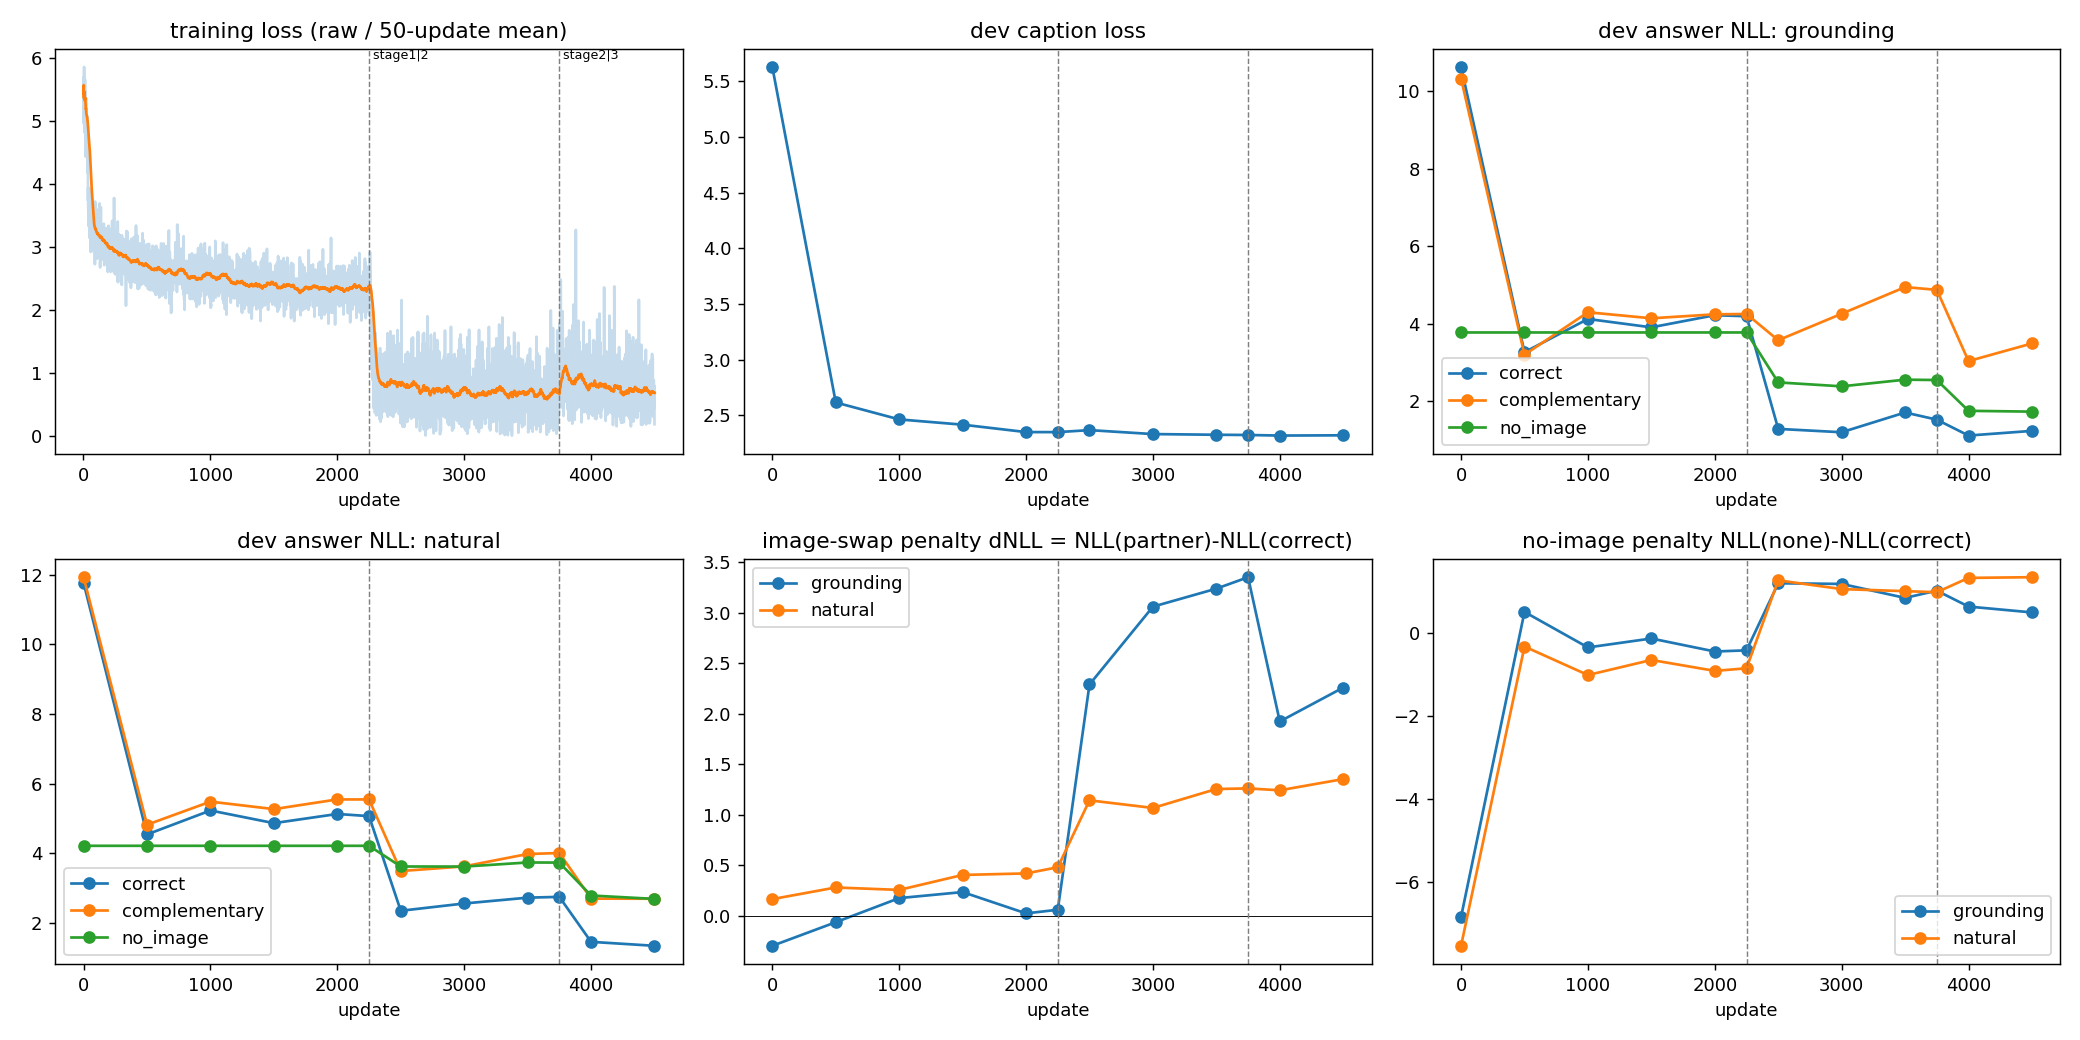

# Report: runs/main

Local subset results, not full-benchmark VQA server scores.

## Calibration
```
{
 "rule": "scale = mean||text token embedding||_2 (training prompts+targets) / mean||connector output||_2 at init (training images); fixed scalar buffer",
 "n_examples": 256,
 "text_mean_l2": 0.8746779561042786,
 "connector_mean_l2_before": 15.955412864685059,
 "scale": 0.0548201393171247,
 "connector_mean_l2_after": 0.8746780157089233
}
```

## Learning curves
![curves](learning_curves.png)
(dashed lines = stage boundaries)

## Final test: grounding suite (64 pairs / 128 questions)

Accuracy / pair-acc / identical / empty in %, with 95% pair-bootstrap CI (4000 resamples). NLL = mean token NLL of the original reference (teacher-forced, no end token). Natural accuracy = VQA soft consensus.


**all** (64 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 64.06 [55.47, 72.66] | 42.19 [31.25, 54.69] | 28.12 [17.19, 39.06] | 0.00 [0.00, 0.00] | 1.049 [0.792, 1.342] | 0.0379 |
| complementary | 14.84 [9.38, 20.31] | 0.00 [0.00, 0.00] | 28.12 [17.19, 39.06] | 0.00 [0.00, 0.00] | 4.186 [3.621, 4.763] | 0.0353 |
| mismatched | 36.72 [28.91, 44.53] | 10.94 [4.69, 18.75] | 62.50 [50.00, 73.48] | 0.00 [0.00, 0.00] | 2.648 [2.260, 3.054] | 0.0381 |
| no_image | 38.28 [32.81, 42.97] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 1.764 [1.551, 1.994] | 0.0183 |

Correct-image advantage over complementary swap: accuracy 49.22 [37.50, 60.94] pts; pair accuracy 42.19 [31.25, 54.69] pts; NLL (complementary - correct) 3.137 [2.409, 3.850].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 128 | 82 | 19 | 27 |
| complementary | 128 | 19 | 82 | 27 |
| mismatched | 128 | 47 | 47 | 34 |
| no_image | 128 | 49 | 49 | 30 |

**presence** (32 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 87.50 [79.69, 93.75] | 75.00 [59.38, 87.50] | 25.00 [12.50, 40.62] | 0.00 [0.00, 0.00] | 0.623 [0.249, 1.079] | 0.0379 |
| complementary | 12.50 [6.25, 20.31] | 0.00 [0.00, 0.00] | 25.00 [12.50, 40.62] | 0.00 [0.00, 0.00] | 5.119 [4.325, 5.872] | 0.0353 |
| mismatched | 51.56 [42.19, 60.94] | 15.62 [3.12, 28.12] | 71.88 [56.25, 87.50] | 0.00 [0.00, 0.00] | 2.529 [1.965, 3.104] | 0.0381 |
| no_image | 50.00 [50.00, 50.00] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 1.397 [1.175, 1.628] | 0.0183 |

Correct-image advantage over complementary swap: accuracy 75.00 [59.38, 87.50] pts; pair accuracy 75.00 [59.38, 87.50] pts; NLL (complementary - correct) 4.496 [3.352, 5.512].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 64 | 56 | 8 | 0 |
| complementary | 64 | 8 | 56 | 0 |
| mismatched | 64 | 33 | 31 | 0 |
| no_image | 64 | 32 | 32 | 0 |

**counting** (32 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 40.62 [29.69, 50.00] | 9.38 [0.00, 21.88] | 31.25 [15.62, 46.88] | 0.00 [0.00, 0.00] | 1.475 [1.192, 1.791] | 0.0379 |
| complementary | 17.19 [9.38, 25.00] | 0.00 [0.00, 0.00] | 31.25 [15.62, 46.88] | 0.00 [0.00, 0.00] | 3.253 [2.591, 4.014] | 0.0353 |
| mismatched | 21.88 [12.50, 32.81] | 6.25 [0.00, 15.62] | 53.12 [34.38, 68.75] | 0.00 [0.00, 0.00] | 2.768 [2.281, 3.294] | 0.0381 |
| no_image | 26.56 [17.19, 35.94] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 2.131 [1.820, 2.478] | 0.0183 |

Correct-image advantage over complementary swap: accuracy 23.44 [7.81, 39.06] pts; pair accuracy 9.38 [0.00, 21.88] pts; NLL (complementary - correct) 1.778 [1.118, 2.467].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 64 | 26 | 11 | 27 |
| complementary | 64 | 11 | 26 | 27 |
| mismatched | 64 | 14 | 16 | 34 |
| no_image | 64 | 17 | 17 | 30 |

## Final test: natural suite (96 pairs / 192 questions)

Accuracy / pair-acc / identical / empty in %, with 95% pair-bootstrap CI (4000 resamples). NLL = mean token NLL of the original reference (teacher-forced, no end token). Natural accuracy = VQA soft consensus.


**all** (96 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 54.53 [48.02, 61.25] | 23.96 [15.62, 33.33] | 47.92 [38.54, 58.33] | 0.00 [0.00, 0.00] | 1.513 [1.213, 1.847] | 0.0436 |
| complementary | 30.78 [25.36, 36.61] | 2.08 [0.00, 5.21] | 47.92 [38.54, 58.33] | 0.00 [0.00, 0.00] | 2.799 [2.380, 3.264] | 0.0423 |
| mismatched | 30.31 [24.79, 35.73] | 2.08 [0.00, 5.21] | 54.17 [43.75, 64.58] | 0.00 [0.00, 0.00] | 2.593 [2.205, 3.011] | 0.0433 |
| no_image | 33.91 [28.59, 39.32] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 2.469 [2.076, 2.890] | 0.0198 |

Correct-image advantage over complementary swap: accuracy 23.75 [14.27, 33.12] pts; pair accuracy 21.88 [12.50, 31.25] pts; NLL (complementary - correct) 1.285 [0.949, 1.645].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 192 | 99 | 51 | 42 |
| complementary | 192 | 51 | 99 | 42 |
| mismatched | 192 | 54 | 58 | 80 |
| no_image | 192 | 60 | 60 | 72 |

**yes/no** (36 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 64.31 [56.94, 71.67] | 22.22 [8.33, 36.11] | 75.00 [61.11, 88.89] | 0.00 [0.00, 0.00] | 0.812 [0.689, 0.936] | 0.0436 |
| complementary | 48.19 [40.83, 55.14] | 2.78 [0.00, 8.33] | 75.00 [61.11, 88.89] | 0.00 [0.00, 0.00] | 1.203 [1.035, 1.399] | 0.0423 |
| mismatched | 50.97 [44.44, 57.50] | 5.56 [0.00, 13.89] | 86.11 [75.00, 97.22] | 0.00 [0.00, 0.00] | 1.280 [1.052, 1.529] | 0.0433 |
| no_image | 51.39 [45.97, 55.83] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 1.281 [1.143, 1.437] | 0.0198 |

Correct-image advantage over complementary swap: accuracy 16.11 [3.46, 29.45] pts; pair accuracy 19.44 [5.56, 33.33] pts; NLL (complementary - correct) 0.391 [0.140, 0.665].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 72 | 43 | 29 | 0 |
| complementary | 72 | 29 | 43 | 0 |
| mismatched | 72 | 34 | 36 | 2 |
| no_image | 72 | 34 | 34 | 4 |

**number** (24 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 46.88 [33.54, 60.00] | 16.67 [4.17, 33.33] | 33.33 [16.67, 54.17] | 0.00 [0.00, 0.00] | 1.843 [1.362, 2.440] | 0.0436 |
| complementary | 27.50 [17.08, 38.33] | 0.00 [0.00, 0.00] | 33.33 [16.67, 54.17] | 0.00 [0.00, 0.00] | 3.341 [2.751, 3.996] | 0.0423 |
| mismatched | 22.08 [12.29, 31.25] | 0.00 [0.00, 0.00] | 50.00 [29.17, 70.83] | 0.00 [0.00, 0.00] | 2.815 [2.209, 3.454] | 0.0433 |
| no_image | 31.67 [21.88, 40.83] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 2.389 [1.747, 3.202] | 0.0198 |

Correct-image advantage over complementary swap: accuracy 19.38 [0.00, 38.75] pts; pair accuracy 16.67 [4.17, 33.33] pts; NLL (complementary - correct) 1.497 [1.047, 1.977].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 48 | 21 | 12 | 15 |
| complementary | 48 | 12 | 21 | 15 |
| mismatched | 48 | 10 | 12 | 26 |
| no_image | 48 | 14 | 14 | 20 |

**other** (36 pairs)

| condition | accuracy | pair acc | identical ans. | empty | ref. NLL | gen s/answer |
|---|---|---|---|---|---|---|
| correct | 49.86 [37.36, 62.50] | 30.56 [16.67, 47.22] | 30.56 [16.67, 47.22] | 0.00 [0.00, 0.00] | 1.994 [1.332, 2.836] | 0.0436 |
| complementary | 15.56 [7.78, 24.45] | 2.78 [0.00, 8.33] | 30.56 [16.67, 47.22] | 0.00 [0.00, 0.00] | 4.033 [3.223, 4.910] | 0.0423 |
| mismatched | 15.14 [8.19, 23.06] | 0.00 [0.00, 0.00] | 25.00 [11.11, 38.89] | 0.00 [0.00, 0.00] | 3.759 [3.029, 4.531] | 0.0433 |
| no_image | 17.92 [10.14, 26.53] | 0.00 [0.00, 0.00] | 100.00 [100.00, 100.00] | 0.00 [0.00, 0.00] | 3.710 [2.971, 4.550] | 0.0198 |

Correct-image advantage over complementary swap: accuracy 34.31 [18.06, 50.56] pts; pair accuracy 27.78 [11.11, 44.44] pts; NLL (complementary - correct) 2.039 [1.300, 2.805].

| condition | n | matches own ref | matches partner ref | neither |
|---|---|---|---|---|
| correct | 72 | 35 | 10 | 27 |
| complementary | 72 | 10 | 35 | 27 |
| mismatched | 72 | 10 | 10 | 52 |
| no_image | 72 | 12 | 12 | 48 |
## Qualitative complementary-image examples

Selection rule (deterministic, no cherry-picking by appearance): within each suite,
pairs are sorted by pair_id and the first k satisfying each category are shown:
  A 'follows image': correct-image predictions right for both questions AND under the
    complementary swap each prediction equals the partner image's reference;
  B 'ignores image': identical predictions for both images of the pair (correct condition);
  C 'fails': at least one wrong prediction under the correct image.

### grounding - A follows image (27 qualifying pairs; showing 3)

![test_count_00003](qualitative/test_count_00003.png)

Question: *How many horses can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 2 | 2 | 1 | 3 | 1 |
| image B | 1 | 1 | 2 | 2 | 1 |


![test_count_00018](qualitative/test_count_00018.png)

Question: *How many dogs can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 2 | 2 | 4 | 3 | 1 |
| image B | 4 | 4 | 2 | 0 | 1 |


![test_count_00023](qualitative/test_count_00023.png)

Question: *How many remotes can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 2 | 2 | 1 | 2 | 1 |
| image B | 1 | 1 | 2 | 2 | 1 |

### grounding - B ignores image (18 qualifying pairs; showing 3)

![test_count_00006](qualitative/test_count_00006.png)

Question: *How many broccoli can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 1 | 4 | 4 | 1 | 1 |
| image B | 3 | 4 | 4 | 2 | 1 |


![test_count_00007](qualitative/test_count_00007.png)

Question: *How many refrigerators can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 1 | 1 | 1 | 1 | 1 |
| image B | 2 | 1 | 1 | 1 | 1 |


![test_count_00009](qualitative/test_count_00009.png)

Question: *How many bottles can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 1 | 1 | 1 | 3 | 1 |
| image B | 2 | 1 | 1 | 3 | 1 |

### grounding - C fails (37 qualifying pairs; showing 3)

![test_count_00000](qualitative/test_count_00000.png)

Question: *How many umbrellas can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 4 | 4 | 3 | 3 | 1 |
| image B | 2 | 3 | 4 | 1 | 1 |


![test_count_00001](qualitative/test_count_00001.png)

Question: *How many hot dogs can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 1 | 1 | 2 | 1 | 1 |
| image B | 4 | 2 | 1 | 3 | 1 |


![test_count_00002](qualitative/test_count_00002.png)

Question: *How many stop signs can you see?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 1 | 1 | 2 | 3 | 1 |
| image B | 4 | 2 | 1 | 3 | 1 |

### natural - A follows image (23 qualifying pairs; showing 3)

![vqa_12754002_452113006](qualitative/vqa_12754002_452113006.png)

Question: *Is there a plaid scarf?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | yes | yes | no | no | no |
| image B | no | no | yes | no | no |


![vqa_179102000_46924000](qualitative/vqa_179102000_46924000.png)

Question: *Is this a right hand or left hand?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | right | right | left | left | right |
| image B | left | left | right | right | right |


![vqa_249786001_33900000](qualitative/vqa_249786001_33900000.png)

Question: *Is this a ski jumping event?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | yes | yes | no | no | no |
| image B | no | no | yes | no | no |

### natural - B ignores image (46 qualifying pairs; showing 3)

![vqa_105973001_142742004](qualitative/vqa_105973001_142742004.png)

Question: *Has the batter hit the ball?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | no | yes | yes | no | no |
| image B | yes | yes | yes | no | no |


![vqa_114504001_560297004](qualitative/vqa_114504001_560297004.png)

Question: *How many carton's of egg's are there?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 2 | 1 | 1 | 0 | 1 |
| image B | 0 | 1 | 1 | 0 | 1 |


![vqa_136466002_568205006](qualitative/vqa_136466002_568205006.png)

Question: *Is the oven warming up?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | yes | yes | yes | no | no |
| image B | no | yes | yes | no | no |

### natural - C fails (73 qualifying pairs; showing 3)

![vqa_105973001_142742004](qualitative/vqa_105973001_142742004.png)

Question: *Has the batter hit the ball?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | no | yes | yes | no | no |
| image B | yes | yes | yes | no | no |


![vqa_114504001_560297004](qualitative/vqa_114504001_560297004.png)

Question: *How many carton's of egg's are there?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | 2 | 1 | 1 | 0 | 1 |
| image B | 0 | 1 | 1 | 0 | 1 |


![vqa_136466002_568205006](qualitative/vqa_136466002_568205006.png)

Question: *Is the oven warming up?*

| item | reference | correct | complementary | mismatched | no image |
|---|---|---|---|---|---|
| image A | yes | yes | yes | no | no |
| image B | no | yes | yes | no | no |

## Resources

- Feature caching (separate from training): 94 s, peak GPU 0.69 GB, 8729+528 images.

| stage | trainable params | training s | peak GPU GB |
|---|---|---|---|
| 1 | 1,837,056 (connector 1,837,056, LoRA 0) | 2859 | 2.52 |
| 2 | 6,424,576 (connector 1,837,056, LoRA 4,587,520) | 2282 | 2.51 |
| 3 | 6,424,576 (connector 1,837,056, LoRA 4,587,520) | 1150 | 2.45 |

Dev-evaluation time during training: 115 s.
Final evaluation: 78 s wall, peak GPU 1.91 GB.

## Analysis notes (fill in after reading the tables above)
- Image use: compare correct vs complementary / mismatched / no-image accuracy and NLL.
- Answer consistency: identical-answer rate and the own/partner/neither table show whether a swap moves predictions toward the partner's answer or yields unsupported answers.
- Limitations: tiny test sets (64 / 96 pairs), wide CIs, one seed, template-derived grounding labels, local VQA scoring; teacher-forced NLL and greedy generation are different measures.

In [ ]:
from IPython.display import Image, Markdown, display
display(Image('runs/main/learning_curves.png'))
display(Markdown(open('runs/main/report.md').read()))

## 8. Optional: 49-token compression (same seed/data/budgets, new connector + adapters)

In [ ]:
!python train.py --run_dir runs/tok49 --tokens 49
!python final_eval.py --run_dir runs/tok49 --tokens 49
!python report.py --run_dir runs/tok49 --coco_root $COCO_ROOT
!python compare_runs.py --a runs/main --b runs/tok49

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100% 311/311 [00:02<00:00, 151.14it/s]
calibration: {'rule': 'scale = mean||text token embedding||_2 (training prompts+targets) / mean||connector output||_2 at init (training images); fixed scalar buffer', 'n_examples': 256, 'text_mean_l2': 0.8746779561042786, 'connector_mean_l2_before': 11.600217819213867, 'scale': 0.07540185621820975, 'connector_mean_l2_after': 0.8746780157089233}
connector gradient check: [{'scale': 65536.0, 'loss': 3.6823723316192627, 'params_without_grad': 0, 'grads_finite': False, 'unscaled_grad_norm': nan}, {'scale': 4096.0, 'loss': 3.6823723316192627, 'params_without_grad': 0, 'grads_finite': False, 'unscaled_grad_norm': nan}, {'scale': 256.0, 'loss': 3.6823723316192627, 'params_without_grad': 0, 'grads_finite': True, 'unscaled_grad_norm': 957.3423485054244}]
sanity checks passed: {'split_isolation': 'ok', 'feature_shape': [4, 196, 768], 'param_counts_stage1': {'connector': 183705

In [ ]:
import os, shutil
os.chdir(WORK)   # WORK is defined in the notebook's setup cell; use '/content/vlm_project' if it isn't defined
shutil.copytree("runs", "results_bundle", dirs_exist_ok=True,
                ignore=shutil.ignore_patterns("ckpt_*.pt"))
if os.path.exists("data/selected"):
    shutil.copytree("data/selected", "results_bundle/selected_data", dirs_exist_ok=True)
shutil.make_archive("results", "zip", "results_bundle")
from google.colab import files
files.download("results.zip")